# Infrastructure sanity
## Load multi-omics table (no transformation)

Purpose:
- Load the preprocessed TCGA-BRCA multi-omics dataset
- Identify patient identifiers and feature columns
- Perform no reshaping, normalization, or filtering

At this stage:
- The dataframe is treated as immutable input
- No modeling assumptions are introduced


In [1]:
import pandas as pd

DATA_DIR = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics"
omics_path = f"{DATA_DIR}/multiomics.csv" 
df = pd.read_csv(omics_path)

print(df.shape)
df.head()

(950, 52006)


,Unnamed: 0,A1BG_RNA,A1CF_RNA,A2M_RNA,A2ML1_RNA,A4GALT_RNA,AAAS_RNA,AACS_RNA,AADAC_RNA,AADACL2_RNA,...,ZW10_METH,ZWILCH_METH,ZWINT_METH,ZXDA_METH,ZXDB_METH,ZXDC_METH,ZYG11B_METH,ZZEF1_METH,ZZZ3_METH,PAM50_subtype
0,TCGA-3C-AAAU-01A,0.603430,0.006980,173.677944,0.243545,4.710933,32.657576,14.401695,0.000000,0.000000,...,0.049608,0.109047,0.057910,0.321347,0.246885,0.087415,0.279483,0.084813,0.062644,LumB
1,TCGA-3C-AALI-01A,0.682114,0.104153,193.408085,0.241419,8.664761,38.951727,9.541005,0.111429,0.000000,...,0.052631,0.105452,0.053972,0.544478,0.374416,0.126821,0.309291,0.071378,0.059151,Her2
2,TCGA-3C-AALJ-01A,0.450187,0.057684,204.877310,0.096761,28.290763,28.007448,15.861093,0.084856,0.000000,...,0.052762,0.133061,0.050686,0.281517,0.306637,0.139180,0.279394,0.069621,0.059139,LumB
3,TCGA-3C-AALK-01A,0.276973,0.020354,261.945450,0.081943,25.766596,30.502503,9.115599,0.399227,0.025697,...,0.050637,0.151608,0.054225,0.463866,0.341055,0.144383,0.273561,0.065023,0.060002,Normal
4,TCGA-4H-AAAK-01A,0.564652,0.008709,290.776611,0.222050,21.368544,41.240604,11.252331,0.051245,0.032984,...,0.056702,0.103626,0.053409,0.500414,0.307140,0.134141,0.268453,0.080721,0.062508,Normal


In [2]:
# Inspect columns
print(df.columns[:10])
print(df.columns[-10:])

Index(['Unnamed: 0', 'A1BG_RNA', 'A1CF_RNA', 'A2M_RNA', 'A2ML1_RNA',
       'A4GALT_RNA', 'AAAS_RNA', 'AACS_RNA', 'AADAC_RNA', 'AADACL2_RNA'],
      dtype='object')
Index(['ZW10_METH', 'ZWILCH_METH', 'ZWINT_METH', 'ZXDA_METH', 'ZXDB_METH',
       'ZXDC_METH', 'ZYG11B_METH', 'ZZEF1_METH', 'ZZZ3_METH', 'PAM50_subtype'],
      dtype='object')


## Explicit patient identifier

The uploaded CSV contains patient identifiers in an unnamed column.
For clarity, reproducibility, and safe merging with clinical data,
this column is explicitly renamed to `patient_id`.

At this stage:
- No rows are dropped
- No reindexing is performed
- The column is kept as a regular dataframe column (not index)


In [3]:
# Rename patient ID column explicitly
assert "Unnamed: 0" in df.columns, "Expected unnamed patient ID column not found"

df = df.rename(columns={"Unnamed: 0": "patient_id"})

# Basic sanity checks
print("Columns after renaming:")
print(df.columns[:5])

print("\nExample patient IDs:")
print(df["patient_id"].head())

# Check uniqueness
n_unique = df["patient_id"].nunique()
n_rows = len(df)

print(f"\nUnique patient IDs: {n_unique}")
print(f"Total rows: {n_rows}")

assert n_unique == n_rows, "Patient IDs are not unique"


Columns after renaming:
Index(['patient_id', 'A1BG_RNA', 'A1CF_RNA', 'A2M_RNA', 'A2ML1_RNA'], dtype='object')

Example patient IDs:
0    TCGA-3C-AAAU-01A
1    TCGA-3C-AALI-01A
2    TCGA-3C-AALJ-01A
3    TCGA-3C-AALK-01A
4    TCGA-4H-AAAK-01A
Name: patient_id, dtype: object

Unique patient IDs: 950
Total rows: 950


## Feature parsing and modality separation

We separate patient identifiers, metadata, and molecular features.
Molecular features are parsed by modality suffix:

- `_RNA`  → RNA expression
- `_CNV`  → Copy number variation
- `_METH` → DNA methylation
- `_SNV`  → Somatic mutations

No filtering, scaling, or transformation is applied at this stage.
This step only establishes structure.


In [4]:
# Identify metadata columns
ID_COL = "patient_id"
META_COLS = ["PAM50_subtype"]  # metadata only, never used for training

# All other columns are candidate molecular features
feature_cols = [c for c in df.columns if c not in [ID_COL] + META_COLS]

# Parse by modality suffix
modalities = {
    "RNA":  [c for c in feature_cols if c.endswith("_RNA")],
    "CNV":  [c for c in feature_cols if c.endswith("_CNV")],
    "METH": [c for c in feature_cols if c.endswith("_METH")],
    "SNV":  [c for c in feature_cols if c.endswith("_SNV")],
}

# Sanity checks
print("Feature counts by modality:")
for m, cols in modalities.items():
    print(f"{m}: {len(cols)}")

# Check for unassigned columns
assigned = set(sum(modalities.values(), []))
unassigned = set(feature_cols) - assigned

print(f"\nUnassigned feature columns: {len(unassigned)}")
if len(unassigned) > 0:
    print(list(unassigned)[:10])


Feature counts by modality:
RNA: 13001
CNV: 13001
METH: 13001
SNV: 13001

Unassigned feature columns: 0


## Dataset Loader

This class constructs a unified tensor representation:

$X ∈ ℝ^{(patients × genes × modalities)}$

- patients are aligned by TCGA barcode
- genes are aligned across all modalities
- modality order is fixed: [RNA, CNV, METH, SNV]

No preprocessing or scaling is applied here.


In [5]:
import numpy as np

class DatasetLoader:
    """
    Minimal dataset loader for TCGA-BRCA multi-omics data.

    Returns:
        X: np.ndarray of shape (patients, genes, modalities)
        patient_index: list of patient IDs
        gene_index: list of gene symbols
    """

    def __init__(self, df, modalities, id_col="patient_id"):
        self.df = df
        self.modalities = modalities
        self.id_col = id_col

        self.modality_order = ["RNA", "CNV", "METH", "SNV"]

        # Sanity check
        for m in self.modality_order:
            assert m in self.modalities, f"Missing modality: {m}"

        self._build_indices()
        self._build_tensor()

    def _build_indices(self):
        # Patient index
        self.patient_index = self.df[self.id_col].tolist()

        # Gene index inferred from column names
        example_modality = self.modalities[self.modality_order[0]]
        self.gene_index = [c.replace(f"_{self.modality_order[0]}", "") for c in example_modality]

        self.n_patients = len(self.patient_index)
        self.n_genes = len(self.gene_index)
        self.n_modalities = len(self.modality_order)

    def _build_tensor(self):
        X = np.zeros((self.n_patients, self.n_genes, self.n_modalities), dtype=np.float32)

        for m_idx, modality in enumerate(self.modality_order):
            cols = self.modalities[modality]
            X[:, :, m_idx] = self.df[cols].values

        self.X = X

    def get_data(self):
        return self.X, self.patient_index, self.gene_index


In [6]:
loader = DatasetLoader(df, modalities)

X, patient_index, gene_index = loader.get_data()

print("X shape:", X.shape)
print("Patients:", len(patient_index))
print("Genes:", len(gene_index))
print("Modalities:", X.shape[2])

# Spot-check
print("\nExample gene:", gene_index[0])
print("Example patient:", patient_index[0])
print("Feature vector:", X[0, 0, :])


X shape: (950, 13001, 4)
Patients: 950
Genes: 13001
Modalities: 4

Example gene: A1BG
Example patient: TCGA-3C-AAAU-01A
Feature vector: [0.60342973 3.         0.67451537 0.        ]


# Clinical & Survival Data: Source Inspection

At this stage, we load and inspect the TCGA-BRCA clinical tables required for
constructing survival outcomes. Two sources are considered:

- `clinical.tsv`: provides baseline demographic and survival fields
  (vital status, days to death, age).
- `follow_up.tsv`: contains longitudinal follow-up information, including
  days to last follow-up, often recorded multiple times per patient.

The goal is to identify the relevant columns and understand table structure
before alignment and aggregation.


In [7]:
import pandas as pd

clinical_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/clinical.tsv"
followup_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/follow_up.tsv"

clinical_df = pd.read_csv(clinical_path, sep="\t", low_memory=False)
followup_df = pd.read_csv(followup_path, sep="\t", low_memory=False)

print("clinical_df shape:", clinical_df.shape)
print("followup_df shape:", followup_df.shape)

print("\nclinical_df columns sample:", clinical_df.columns[:30].tolist())
print("\nfollowup_df columns sample:", followup_df.columns[:30].tolist())


clinical_df shape: (5506, 210)
followup_df shape: (9337, 198)

clinical_df columns sample: ['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.premature_at_birth', 'demographic.race', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.weeks_gestation_at_birth']

followup_df columns sample: ['project.project_

## Clinical & Survival Data: Minimal Column Extraction

In this step, we extract a strictly minimal set of clinical variables required
for downstream survival analysis. The goal is to reduce the high-dimensional
TCGA clinical tables to narrow, interpretable dataframes that can later be
aligned with the 950-patient multi-omics cohort.

We intentionally avoid any aggregation, censoring logic, or patient filtering
at this stage. This separation ensures that survival definitions remain
explicit and auditable.


In [ ]:
# -------------------------------
# Minimal clinical extraction
# -------------------------------

# Columns we need from clinical.tsv
clinical_cols = [
    "cases.submitter_id",          # patient ID
    "demographic.vital_status",    # Alive / Dead
    "demographic.days_to_death",   # may be NaN
    "demographic.age_at_index"     # optional covariate
]

clinical_min = (
    clinical_df
    .loc[:, clinical_cols]
    .rename(columns={
        "cases.submitter_id": "patient_id",
        "demographic.vital_status": "vital_status",
        "demographic.days_to_death": "days_to_death",
        "demographic.age_at_index": "age_at_diagnosis"
    })
)

print("clinical_min shape:", clinical_min.shape)
clinical_min.head()


clinical_min shape: (5506, 4)


,patient_id,vital_status,days_to_death,age_at_diagnosis
0,TCGA-E2-A1IU,Alive,'--,60
1,TCGA-E2-A1IU,Alive,'--,60
2,TCGA-E2-A1IU,Alive,'--,60
3,TCGA-A1-A0SB,Alive,'--,70
4,TCGA-A2-A04W,Alive,'--,50


In [9]:
# Columns we need from follow_up.tsv
followup_cols = [
    "cases.submitter_id",           # patient ID
    "follow_ups.days_to_follow_up"  # follow-up time
]

followup_min = (
    followup_df
    .loc[:, followup_cols]
    .rename(columns={
        "cases.submitter_id": "patient_id",
        "follow_ups.days_to_follow_up": "days_to_follow_up"
    })
)

print("followup_min shape:", followup_min.shape)
followup_min.head()


followup_min shape: (9337, 2)


,patient_id,days_to_follow_up
0,TCGA-E2-A1IU,337
1,TCGA-E2-A1IU,127
2,TCGA-E2-A1IU,337
3,TCGA-E2-A1IU,'--
4,TCGA-E2-A1IU,'--


## Aggregating Follow-Up Time Per Patient

TCGA follow-up data are longitudinal, with multiple follow-up entries per patient.
To prepare for survival analysis, we aggregate follow-up information by retaining
the maximum recorded follow-up time for each patient.

Only numeric follow-up times are considered. Explicit missing values ('--') are
removed prior to aggregation to ensure correctness and transparency.


In [ ]:
# -------------------------------
# Aggregate follow-up time
# -------------------------------

# Replace TCGA missing value marker with NaN
followup_clean = followup_min.replace("'--", np.nan)

# Convert to numeric
followup_clean["days_to_follow_up"] = pd.to_numeric(
    followup_clean["days_to_follow_up"],
    errors="coerce"
)

# Aggregate: maximum follow-up time per patient
followup_agg = (
    followup_clean
    .groupby("patient_id", as_index=False)
    .agg(max_days_to_follow_up=("days_to_follow_up", "max"))
)

print("Aggregated follow-up shape:", followup_agg.shape)
followup_agg.head()


Aggregated follow-up shape: (1083, 2)


,patient_id,max_days_to_follow_up
0,TCGA-3C-AAAU,4047.0
1,TCGA-3C-AALI,4005.0
2,TCGA-3C-AALJ,1474.0
3,TCGA-3C-AALK,1448.0
4,TCGA-4H-AAAK,348.0


## Cleaning Clinical Survival Fields

Clinical data from TCGA may contain multiple records per patient due to repeated
diagnostic or administrative entries. Before constructing survival variables,
we first consolidate clinical information to a single record per patient.

At this stage, we retain:
- vital status
- days to death (if available)
- age at diagnosis

Missing values encoded as '--' are explicitly converted to NaN.
No survival time or censoring logic is applied yet.


In [ ]:
# -------------------------------
# Clean clinical data
# -------------------------------

clinical_clean = clinical_min.copy()

# Replace TCGA missing value marker
clinical_clean = clinical_clean.replace("'--", np.nan)

# Convert days_to_death to numeric
clinical_clean["days_to_death"] = pd.to_numeric(
    clinical_clean["days_to_death"],
    errors="coerce"
)

# Ensure age is numeric
clinical_clean["age_at_diagnosis"] = pd.to_numeric(
    clinical_clean["age_at_diagnosis"],
    errors="coerce"
)

# Collapse to one row per patient
clinical_agg = (
    clinical_clean
    .groupby("patient_id", as_index=False)
    .agg(
        vital_status=("vital_status", "first"),
        days_to_death=("days_to_death", "min"),
        age_at_diagnosis=("age_at_diagnosis", "first")
    )
)

print("Aggregated clinical shape:", clinical_agg.shape)
clinical_agg.head()


Aggregated clinical shape: (1084, 4)


,patient_id,vital_status,days_to_death,age_at_diagnosis
0,TCGA-3C-AAAU,Alive,NaN,55
1,TCGA-3C-AALI,Alive,NaN,50
2,TCGA-3C-AALJ,Alive,NaN,62
3,TCGA-3C-AALK,Alive,NaN,52
4,TCGA-4H-AAAK,Alive,NaN,50


## Aligning Clinical and Multi-Omics Cohorts

TCGA clinical data are indexed at the patient level (12-character barcode),
whereas molecular data are indexed at the sample level (16-character barcode).

Before constructing survival variables, we explicitly align patient identifiers
between the multi-omics cohort and the clinical tables and quantify cohort overlap.

This step determines the maximum number of patients for whom survival-based
evaluation is possible.


In [ ]:
# -------------------------------
# Align clinical with multi-omics cohort
# -------------------------------

# Derive patient_id from multi-omics sample IDs
multiomics_patients = (
    df["patient_id"]
    .str.slice(0, 12)
    .unique()
)

print("Multi-omics unique patients:", len(multiomics_patients))

# Clinical patients
clinical_patients = clinical_agg["patient_id"].unique()
print("Clinical patients:", len(clinical_patients))

# Intersection
common_patients = set(multiomics_patients) & set(clinical_patients)
print("Patients with both omics + clinical data:", len(common_patients))


Multi-omics unique patients: 944
Clinical patients: 1084
Patients with both omics + clinical data: 936


## Survival Variable Construction (Raw)

We now construct raw survival variables for patients with both molecular and
clinical data. Survival time is defined as the time from diagnosis to either
death or last follow-up, and event status indicates whether death was observed.

At this stage, no patients are excluded. Missing or inconsistent values are
explicitly retained to allow transparent accounting of cohort attrition in
subsequent steps.


In [ ]:
# -------------------------------
# Raw survival variable construction
# -------------------------------

# Restrict to intersecting patients only
clinical_surv = clinical_agg[
    clinical_agg["patient_id"].isin(common_patients)
].copy()

followup_surv = followup_agg[
    followup_agg["patient_id"].isin(common_patients)
].copy()

# Merge clinical + follow-up
surv_df = clinical_surv.merge(
    followup_surv,
    on="patient_id",
    how="left"
)

# Define event indicator
surv_df["event"] = surv_df["vital_status"].map({
    "Dead": 1,
    "Alive": 0
})

# Define survival time
surv_df["time"] = surv_df[["days_to_death", "max_days_to_follow_up"]].min(axis=1)

# Inspect
print("Survival dataframe shape:", surv_df.shape)
surv_df.head()


Survival dataframe shape: (936, 7)


,patient_id,vital_status,days_to_death,age_at_diagnosis,max_days_to_follow_up,event,time
0,TCGA-3C-AAAU,Alive,NaN,55,4047.0,0,4047.0
1,TCGA-3C-AALI,Alive,NaN,50,4005.0,0,4005.0
2,TCGA-3C-AALJ,Alive,NaN,62,1474.0,0,1474.0
3,TCGA-3C-AALK,Alive,NaN,52,1448.0,0,1448.0
4,TCGA-4H-AAAK,Alive,NaN,50,348.0,0,348.0


In [14]:
# Missingness summary
print("\nMissing values:")
print(surv_df[["time", "event", "age_at_diagnosis"]].isna().sum())

# Basic sanity checks
print("\nEvent distribution:")
print(surv_df["event"].value_counts(dropna=False))

print("\nTime range:")
print(surv_df["time"].describe())



Missing values:
time                0
event               0
age_at_diagnosis    0
dtype: int64

Event distribution:
event
0    812
1    124
Name: count, dtype: int64

Time range:
count     936.000000
mean     1225.941239
std      1211.838404
min        -7.000000
25%       434.750000
50%       793.500000
75%      1664.750000
max      8605.000000
Name: time, dtype: float64


## Sanity check: negative survival times

Although TCGA clinical data are widely used, they are known to contain
occasional inconsistencies in reported time-to-event variables. In particular,
negative values can arise due to differences in how dates are indexed across
clinical fields.

Before defining the final survival cohort, we explicitly identify and inspect
patients with negative survival times.


In [ ]:
# -------------------------------
# Inspect negative survival times
# -------------------------------

neg_time_df = surv_df[surv_df["time"] < 0].copy()

print("Number of patients with negative survival time:", neg_time_df.shape[0])

# Percentage of cohort affected
print(
    f"Percentage affected: {100 * neg_time_df.shape[0] / surv_df.shape[0]:.2f}%"
)
neg_time_df[[
    "patient_id",
    "vital_status",
    "days_to_death",
    "max_days_to_follow_up",
    "time"
]]



Number of patients with negative survival time: 1
Percentage affected: 0.11%


,patient_id,vital_status,days_to_death,max_days_to_follow_up,time
913,TCGA-PL-A8LV,Alive,NaN,-7.0,-7.0


## Final survival cohort definition

One patient exhibited a negative survival time due to inconsistencies in TCGA
date indexing. Because negative survival times are not biologically meaningful
and cannot be handled by standard survival models, this patient was excluded.

This affected 1 out of 936 patients (<0.2% of the cohort). All remaining patients
had valid, non-negative survival times and complete event indicators.


In [ ]:
# -------------------------------
# Finalize survival cohort
# -------------------------------

# Exclude negative survival times
surv_df_final = surv_df[surv_df["time"] >= 0].copy()

print("Final survival cohort shape:", surv_df_final.shape)

print("\nEvent distribution:")
print(surv_df_final["event"].value_counts())

print("\nTime summary:")
print(surv_df_final["time"].describe())


Final survival cohort shape: (935, 7)

Event distribution:
event
0    811
1    124
Name: count, dtype: int64

Time summary:
count     935.000000
mean     1227.259893
std      1211.814895
min         0.000000
25%       436.000000
50%       795.000000
75%      1667.500000
max      8605.000000
Name: time, dtype: float64


## Save frozen survival table (to prevent re-cleaning)

We save a finalized survival dataframe aligned to the multi-omics cohort.
This file becomes the single source of truth for all survival-based evaluation.


In [17]:
# -------------------------------
# Persist finalized survival labels
# -------------------------------
SURV_OUT = "tcga_brca_survival_final.csv"

# Keep only what we need for evaluation
survival_export = surv_df_final[[
    "patient_id",         # 12-char
    "time",
    "event",
    "age_at_diagnosis"
]].copy()

survival_export.to_csv(SURV_OUT, index=False)
print("Saved:", SURV_OUT, "shape:", survival_export.shape)


Saved: tcga_brca_survival_final.csv shape: (935, 4)


In [18]:
# Reload survival df
survival_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/tcga_brca_survival_final.csv"
surv_df_final = pd.read_csv(survival_path, low_memory=False)

## Align multi-omics tensors with survival labels

At this stage, we align the multi-omics representation tensor with the finalized
survival dataframe. This step is critical to ensure that:

- each row in the model input corresponds to exactly one patient,
- patient ordering is consistent across omics features and clinical labels,
- downstream modeling and evaluation operate on a coherent cohort.

Because TCGA clinical files use 12-character patient identifiers (e.g. `TCGA-3C-AAAU`)
while the multi-omics table uses sample-level identifiers
(e.g. `TCGA-3C-AAAU-01A`), we explicitly construct a shortened patient identifier
to perform a deterministic inner join.

The output of this step is:
- `X_surv`: multi-omics tensor aligned to survival data
- `surv_aligned`: survival dataframe reordered to match `X_surv`
- `patient_ids_aligned`: patient identifiers defining the final modeling cohort

These objects form the **fixed input** for all subsequent models and evaluations.


In [19]:
# -------------------------------------------------
# Align multi-omics tensor with survival dataframe
# -------------------------------------------------

# Assumptions:
# - X: np.ndarray of shape (N, G, M) from DatasetLoader
# - patient_index: list/array of length N with full IDs (e.g. TCGA-XX-XXXX-01A)
# - survival_export: dataframe saved earlier with columns:
#   ['patient_id', 'time', 'event', 'age_at_diagnosis']

import pandas as pd
import numpy as np

# --- 1. Build multi-omics patient dataframe ---
omics_patients = pd.DataFrame({
    "patient_id_full": patient_index,
})

# Extract 12-character TCGA patient ID for joining
omics_patients["patient_id"] = omics_patients["patient_id_full"].str.slice(0, 12)

print("Multi-omics patients:", omics_patients.shape[0])
print("Unique short IDs:", omics_patients["patient_id"].nunique())

# --- 2. Merge with survival dataframe ---
merged = omics_patients.merge(
    survival_export,
    on="patient_id",
    how="inner"
)

print("Patients with omics + survival:", merged.shape[0])

# --- 3. Reorder X to match merged patient order ---
# Create index mapping from original omics order
omics_index_map = {
    pid: idx for idx, pid in enumerate(omics_patients["patient_id_full"])
}

aligned_indices = merged["patient_id_full"].map(omics_index_map).values

X_surv = X[aligned_indices]

# --- 4. Final aligned survival dataframe ---
surv_aligned = merged[[
    "patient_id",
    "time",
    "event",
    "age_at_diagnosis"
]].reset_index(drop=True)

patient_ids_aligned = merged["patient_id_full"].values

# --- 5. Sanity checks ---
print("\n=== Final alignment summary ===")
print("X_surv shape:", X_surv.shape)
print("Survival shape:", surv_aligned.shape)

assert X_surv.shape[0] == surv_aligned.shape[0]
# assert not np.isnan(X_surv).any(), "NaNs detected in X_surv"

print("\nEvent distribution:")
print(surv_aligned["event"].value_counts())

print("\nTime range:")
print(surv_aligned["time"].describe())

print("\nAlignment successful. Ready for modeling.")


Multi-omics patients: 950
Unique short IDs: 944
Patients with omics + survival: 941

=== Final alignment summary ===
X_surv shape: (941, 13001, 4)
Survival shape: (941, 4)

Event distribution:
event
0    817
1    124
Name: count, dtype: int64

Time range:
count     941.000000
mean     1224.209352
std      1208.635407
min         0.000000
25%       439.000000
50%       792.000000
75%      1649.000000
max      8605.000000
Name: time, dtype: float64

Alignment successful. Ready for modeling.


### NaN diagnostics in aligned multi-omics tensor

Before any modeling decisions are made, we explicitly quantify missing values
in the aligned multi-omics tensor.

This step answers:
- whether NaNs originate from specific omics layers,
- whether NaNs are rare or systematic,
- whether NaNs are gene-specific or widespread.

No imputation or correction is applied at this stage.
This diagnostic step ensures that downstream handling of missing values is
intentional, documented, and justified.


In [20]:
# -------------------------------------------------
# NaN diagnostics per modality
# -------------------------------------------------

import numpy as np
import pandas as pd

modalities = ["RNA", "CNV", "METH", "SNV"]

print("X_surv shape:", X_surv.shape)
print()

# --- 1. Overall NaN count ---
total_nans = np.isnan(X_surv).sum()
total_elements = X_surv.size

print(f"Total NaNs: {total_nans}")
print(f"Total elements: {total_elements}")
print(f"NaN percentage: {100 * total_nans / total_elements:.4f}%\n")

# --- 2. NaNs per modality ---
nan_summary = []

for m_idx, modality in enumerate(modalities):
    modality_slice = X_surv[:, :, m_idx]
    nan_count = np.isnan(modality_slice).sum()
    nan_pct = 100 * nan_count / modality_slice.size
    
    nan_summary.append({
        "modality": modality,
        "nan_count": nan_count,
        "nan_percentage": nan_pct
    })

nan_df = pd.DataFrame(nan_summary)
display(nan_df)

# --- 3. Patients affected by NaNs ---
patients_with_nan = np.isnan(X_surv).any(axis=(1, 2)).sum()
print(f"\nPatients with at least one NaN: {patients_with_nan} / {X_surv.shape[0]}")

# --- 4. Genes affected by NaNs ---
genes_with_nan = np.isnan(X_surv).any(axis=(0, 2)).sum()
print(f"Genes with at least one NaN: {genes_with_nan} / {X_surv.shape[1]}")


X_surv shape: (941, 13001, 4)

Total NaNs: 1252128
Total elements: 48935764
NaN percentage: 2.5587%



,modality,nan_count,nan_percentage
0,RNA,0,0.00000
1,CNV,0,0.00000
2,METH,1252128,10.23487
3,SNV,0,0.00000



Patients with at least one NaN: 941 / 941
Genes with at least one NaN: 6633 / 13001


### Handling missing methylation values

After alignment with survival data, missing values were observed exclusively
in the DNA methylation modality. This missingness arises from incomplete
probe-to-gene coverage in the Illumina HM450 platform rather than from
data corruption or patient-level absence.

To ensure a fixed-dimensional representation across all genes and patients,
missing methylation values are explicitly set to zero. This choice reflects
the absence of promoter-associated methylation signal for genes without
corresponding probes and preserves compatibility with autoencoder-based
models and graph-structured architectures.

No missing values were observed in RNA expression, copy number variation,
or somatic mutation modalities.


In [21]:
# -------------------------------------------------
# Explicit NaN handling: methylation only
# -------------------------------------------------

# Modality order: [RNA, CNV, METH, SNV]
METH_IDX = 2

nan_before = np.isnan(X_surv[:, :, METH_IDX]).sum()

# Zero-fill methylation NaNs
X_surv[:, :, METH_IDX] = np.nan_to_num(
    X_surv[:, :, METH_IDX],
    nan=0.0
)

nan_after = np.isnan(X_surv[:, :, METH_IDX]).sum()

print(f"Methylation NaNs before: {nan_before}")
print(f"Methylation NaNs after:  {nan_after}")

# Final safety check
assert not np.isnan(X_surv).any(), "NaNs still present after methylation fix"
print("\nX_surv is now fully dense and model-ready.")


Methylation NaNs before: 1252128
Methylation NaNs after:  0

X_surv is now fully dense and model-ready.


## Additional Clinical Info

In [22]:
clinical_all_cols = clinical_df.columns
print(clinical_all_cols.tolist())

['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.premature_at_birth', 'demographic.race', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.weeks_gestation_at_birth', 'demographic.year_of_birth', 'demographic.year_of_death', 'diagnoses.adrenal_hormone', 'diagnoses.age_at_diagnosis', 'diagnoses.ajcc_clini

In [ ]:
# -----------------------------------------------
# Additional clinical covariates (stage, grade, receptors)
# -----------------------------------------------
import numpy as np
import pandas as pd

# 1. Define candidate columns (from clinicaldf.columns)
clinical_cov_cols = [
    "cases.submitter_id",          # patient ID
    # Stage / T / N / M
    "diagnoses.ajcc_pathologic_stage",
    "diagnoses.ajcc_pathologic_t",
    "diagnoses.ajcc_pathologic_n",
    "diagnoses.ajcc_pathologic_m",
    # Grade
    "diagnoses.tumor_grade",
    # Receptor status (IHC)
    "diagnoses.er_status_by_ihc",
    "diagnoses.pr_status_by_ihc",
    "diagnoses.her2_status_by_ihc",
]

# Keep only columns that actually exist in this clinical file
available_cov_cols = [c for c in clinical_cov_cols if c in clinical_df.columns]
print("Requested clinical covariates:", len(clinical_cov_cols))
print("Available clinical covariates:", len(available_cov_cols))
print("Available columns:", available_cov_cols)

# 2. Subset and rename submitter ID -> patientid
clinical_cov = clinical_df.loc[:, available_cov_cols].copy()
clinical_cov = clinical_cov.rename(columns={"cases.submitter_id": "patientid"})

# 3. Normalize TCGA missing markers to NaN
# (TCGA often uses "--" or "[Not Available]" etc.)
missing_markers = ["--", "[Not Available]", "[Unknown]", "[Not Applicable]"]
clinical_cov = clinical_cov.replace(missing_markers, np.nan)

# 4. Collapse to one row per patient
#    For repeated diagnoses per patient, we take the first non-null entry for each field.
agg_dict = {}
for col in clinical_cov.columns:
    if col == "patientid":
        continue
    agg_dict[col] = "first"

clinical_cov_agg = (
    clinical_cov
    .groupby("patientid", as_index=False)
    .agg(agg_dict)
)

print("Aggregated clinical covariate table shape:", clinical_cov_agg.shape)
clinical_cov_agg.head()


Requested clinical covariates: 9
Available clinical covariates: 6
Available columns: ['cases.submitter_id', 'diagnoses.ajcc_pathologic_stage', 'diagnoses.ajcc_pathologic_t', 'diagnoses.ajcc_pathologic_n', 'diagnoses.ajcc_pathologic_m', 'diagnoses.tumor_grade']
Aggregated clinical covariate table shape: (1084, 6)


,patientid,diagnoses.ajcc_pathologic_stage,diagnoses.ajcc_pathologic_t,diagnoses.ajcc_pathologic_n,diagnoses.ajcc_pathologic_m,diagnoses.tumor_grade
0,TCGA-3C-AAAU,'--,'--,'--,'--,'--
1,TCGA-3C-AALI,Stage IIB,T2,N1a,M0,'--
2,TCGA-3C-AALJ,Stage IIB,T2,N1a,M0,'--
3,TCGA-3C-AALK,Stage IA,T1c,N0 (i+),M0,'--
4,TCGA-4H-AAAK,Stage IIIA,T2,N2a,M0,'--


In [24]:
# Inspect missingness and unique values for each covariate
cov_cols = [
    "diagnoses.ajcc_pathologic_stage",
    "diagnoses.ajcc_pathologic_t",
    "diagnoses.ajcc_pathologic_n",
    "diagnoses.ajcc_pathologic_m",
    "diagnoses.tumor_grade",
]

print("Missing counts:")
print(clinical_cov_agg[cov_cols].isna().sum())

print("\nUnique values (first 20) per column:")
for c in cov_cols:
    vals = clinical_cov_agg[c].dropna().unique()
    print(f"\n{c} (n={len(vals)} unique):")
    print(vals[:20])


Missing counts:
diagnoses.ajcc_pathologic_stage    0
diagnoses.ajcc_pathologic_t        0
diagnoses.ajcc_pathologic_n        0
diagnoses.ajcc_pathologic_m        0
diagnoses.tumor_grade              0
dtype: int64

Unique values (first 20) per column:

diagnoses.ajcc_pathologic_stage (n=13 unique):
["'--" 'Stage IIB' 'Stage IA' 'Stage IIIA' 'Stage IV' 'Stage IIA'
 'Stage I' 'Stage IB' 'Stage IIIC' 'Stage IIIB' 'Stage 0' 'Stage X'
 'Stage II']

diagnoses.ajcc_pathologic_t (n=17 unique):
["'--" 'T2' 'T1c' 'T3' 'T1' 'T4b' 'T1b' 'Tis (LCIS)' 'T1a' 'T4d' 'T4' 'TX'
 'T2b' 'T3a' 'Tis' 'Tis (DCIS)' 'T2a']

diagnoses.ajcc_pathologic_n (n=16 unique):
["'--" 'N1a' 'N0 (i+)' 'N2a' 'N0' 'NX' 'N0 (i-)' 'N1' 'N1mi' 'N3a' 'N2'
 'N3' 'N1b' 'N1c' 'N0 (mol+)' 'N3b']

diagnoses.ajcc_pathologic_m (n=5 unique):
["'--" 'M0' 'M1' 'MX' 'cM0 (i+)']

diagnoses.tumor_grade (n=2 unique):
["'--" 'Not Reported']


In [25]:
# -----------------------------------------------
# Clean and recode stage / T / N / M
# -----------------------------------------------

clinical_cov_clean = clinical_cov_agg.copy()

# 1. Rename columns to simpler names for downstream use
clinical_cov_clean = clinical_cov_clean.rename(columns={
    "diagnoses.ajcc_pathologic_stage": "stage_pathologic_overall_raw",
    "diagnoses.ajcc_pathologic_t": "t_pathologic_raw",
    "diagnoses.ajcc_pathologic_n": "n_pathologic_raw",
    "diagnoses.ajcc_pathologic_m": "m_pathologic_raw",
    "diagnoses.tumor_grade": "grade_pathologic_raw",
})

# Helper: strip quotes and whitespace
def _clean_str(x):
    if isinstance(x, str):
        return x.strip().strip("'").strip()
    return x

for col in [
    "stage_pathologic_overall_raw",
    "t_pathologic_raw",
    "n_pathologic_raw",
    "m_pathologic_raw",
    "grade_pathologic_raw",
]:
    clinical_cov_clean[col] = clinical_cov_clean[col].apply(_clean_str)

# 2. Overall stage: map to ordered categories / integers
stage_map = {
    "Stage 0": 0,
    "Stage I": 1,
    "Stage IA": 1,
    "Stage IB": 1,
    "Stage II": 2,
    "Stage IIA": 2,
    "Stage IIB": 2,
    "Stage III": 3,
    "Stage IIIA": 3,
    "Stage IIIB": 3,
    "Stage IIIC": 3,
    "Stage IV": 4,
    "Stage X": np.nan,  # unknown stage
    "--": np.nan,
    "": np.nan,
}

clinical_cov_clean["stage_pathologic_overall_num"] = clinical_cov_clean["stage_pathologic_overall_raw"].map(stage_map)

# 3. T / N / M: simplify by removing decorations like "(i+)", "(i-)", "(mol+)", "cM0 (i+)"
import re

def _simplify_tnm(x):
    if not isinstance(x, str):
        return x
    x = x.strip()
    if x in ["--", ""]:
        return np.nan
    # remove text in parentheses, e.g. "N0 (i+)" -> "N0"
    x = re.sub(r"\s*\\(.*\\)", "", x)
    return x

for col_raw, col_clean in [
    ("t_pathologic_raw", "t_pathologic_base"),
    ("n_pathologic_raw", "n_pathologic_base"),
    ("m_pathologic_raw", "m_pathologic_base"),
]:
    clinical_cov_clean[col_clean] = clinical_cov_clean[col_raw].apply(_simplify_tnm)

# 4. Grade: mark as missing (no usable information in this cohort)
clinical_cov_clean["grade_pathologic"] = np.nan

print("Head of cleaned clinical covariates:")
clinical_cov_clean.head()

print("\nValue counts for stage_pathologic_overall_raw:")
print(clinical_cov_clean["stage_pathologic_overall_raw"].value_counts())

print("\nValue counts for t_pathologic_base:")
print(clinical_cov_clean["t_pathologic_base"].value_counts())

print("\nValue counts for n_pathologic_base:")
print(clinical_cov_clean["n_pathologic_base"].value_counts())

print("\nValue counts for m_pathologic_base:")
print(clinical_cov_clean["m_pathologic_base"].value_counts())


Head of cleaned clinical covariates:

Value counts for stage_pathologic_overall_raw:
stage_pathologic_overall_raw
Stage IIA     333
Stage IIB     230
Stage IIIA    136
--            100
Stage IA       84
Stage I        80
Stage IIIC     56
Stage IIIB     23
Stage IV       18
Stage II        7
Stage X         7
Stage IB        6
Stage 0         4
Name: count, dtype: int64

Value counts for t_pathologic_base:
t_pathologic_base
T2            577
T1c           200
T3            117
T1             37
T4b            23
T1b            16
T4              8
T1a             3
T4d             3
Tis (LCIS)      2
TX              2
Tis             2
T2b             1
T3a             1
Tis (DCIS)      1
T2a             1
Name: count, dtype: int64

Value counts for n_pathologic_base:
n_pathologic_base
N0           315
N1a          154
N0 (i-)      141
N1           107
N2a           57
N2            52
N3a           40
N1mi          31
N0 (i+)       28
N1b           23
N3            22
NX            1

In [26]:
# -----------------------------------------------
# Refine TNM simplification: remove all parentheses,
# and normalize special cases like N0 (i+), cM0 (i+), Tis variants
# -----------------------------------------------
import re
import numpy as np

clinical_cov_clean_refined = clinical_cov_clean.copy()

def _simplify_tnm_full(x):
    if not isinstance(x, str):
        return x
    x = x.strip()
    if x in ["--", ""]:
        return np.nan
    # remove text in parentheses, e.g. "N0 (i+)" -> "N0", "cM0 (i+)" -> "cM0"
    x = re.sub(r"\s*\(.*\)", "", x)
    x = x.strip()
    return x

for col_raw, col_clean in [
    ("t_pathologic_raw", "t_pathologic_base"),
    ("n_pathologic_raw", "n_pathologic_base"),
    ("m_pathologic_raw", "m_pathologic_base"),
]:
    clinical_cov_clean_refined[col_clean] = clinical_cov_clean_refined[col_raw].apply(_simplify_tnm_full)

# Normalize a few known variants explicitly
# Tis variants -> "Tis"
clinical_cov_clean_refined["t_pathologic_base"] = clinical_cov_clean_refined["t_pathologic_base"].replace({
    "Tis (LCIS)": "Tis",
    "Tis (DCIS)": "Tis",
})

# N0 variants -> "N0"
clinical_cov_clean_refined["n_pathologic_base"] = clinical_cov_clean_refined["n_pathologic_base"].replace({
    "N0 (i-)": "N0",
    "N0 (i+)": "N0",
    "N0 (mol+)": "N0",
})

# cM0 -> M0
clinical_cov_clean_refined["m_pathologic_base"] = clinical_cov_clean_refined["m_pathologic_base"].replace({
    "cM0": "M0",
    "cM0 (i+)": "M0",
})

print("Value counts after refinement:\n")

print("stage_pathologic_overall_raw:")
print(clinical_cov_clean_refined["stage_pathologic_overall_raw"].value_counts(), "\n")

print("t_pathologic_base:")
print(clinical_cov_clean_refined["t_pathologic_base"].value_counts(), "\n")

print("n_pathologic_base:")
print(clinical_cov_clean_refined["n_pathologic_base"].value_counts(), "\n")

print("m_pathologic_base:")
print(clinical_cov_clean_refined["m_pathologic_base"].value_counts(), "\n")


Value counts after refinement:

stage_pathologic_overall_raw:
stage_pathologic_overall_raw
Stage IIA     333
Stage IIB     230
Stage IIIA    136
--            100
Stage IA       84
Stage I        80
Stage IIIC     56
Stage IIIB     23
Stage IV       18
Stage II        7
Stage X         7
Stage IB        6
Stage 0         4
Name: count, dtype: int64 

t_pathologic_base:
t_pathologic_base
T2     577
T1c    200
T3     117
T1      37
T4b     23
T1b     16
T4       8
Tis      5
T1a      3
T4d      3
TX       2
T2b      1
T3a      1
T2a      1
Name: count, dtype: int64 

n_pathologic_base:
n_pathologic_base
N0      485
N1a     154
N1      107
N2a      57
N2       52
N3a      40
N1mi     31
N1b      23
N3       22
NX       18
N1c       2
N3b       2
Name: count, dtype: int64 

m_pathologic_base:
m_pathologic_base
M0    833
MX    141
M1     19
Name: count, dtype: int64 



In [27]:
# Ensure survival and clinical tables use the same patient ID column name

clinical_cov_clean_refined = clinical_cov_clean_refined.rename(columns={"patientid": "patient_id"})

print(clinical_cov_clean_refined.columns)


Index(['patient_id', 'stage_pathologic_overall_raw', 't_pathologic_raw',
       'n_pathologic_raw', 'm_pathologic_raw', 'grade_pathologic_raw',
       'stage_pathologic_overall_num', 't_pathologic_base',
       'n_pathologic_base', 'm_pathologic_base', 'grade_pathologic'],
      dtype='object')


In [28]:
# -----------------------------------------------
# Build patient-level clinical_core table
# -----------------------------------------------

# survdffinal: patientid, time, event, ageatdiagnosis (final survival cohort)
print("Final survival cohort shape:", surv_df_final.shape)

# Select only the cleaned covariate columns we care about
cov_cols_keep = [
    "patient_id",
    "stage_pathologic_overall_raw",
    "stage_pathologic_overall_num",
    "t_pathologic_raw",
    "t_pathologic_base",
    "n_pathologic_raw",
    "n_pathologic_base",
    "m_pathologic_raw",
    "m_pathologic_base",
    "grade_pathologic_raw",
    "grade_pathologic",
]

clinical_cov_final = clinical_cov_clean_refined[cov_cols_keep].copy()

# Merge survival and clinical covariates on 12-char patientid
clinical_core = surv_df_final.merge(
    clinical_cov_final,
    on="patient_id",
    how="left"
)

print("clinical_core shape:", clinical_core.shape)
clinical_core.head()

# Quick missingness check (should be none or very few, except grade_pathologic)
print("\nMissingness in clinical_core:")
print(clinical_core.isna().sum())


Final survival cohort shape: (935, 4)
clinical_core shape: (935, 14)

Missingness in clinical_core:
patient_id                        0
time                              0
event                             0
age_at_diagnosis                  0
stage_pathologic_overall_raw      0
stage_pathologic_overall_num     91
t_pathologic_raw                  0
t_pathologic_base                74
n_pathologic_raw                  0
n_pathologic_base                75
m_pathologic_raw                  0
m_pathologic_base                75
grade_pathologic_raw              0
grade_pathologic                935
dtype: int64


In [29]:
# -----------------------------------------------
# Align clinical_core with X_surv / surv_aligned
# -----------------------------------------------
import pandas as pd
import numpy as np

print("Length of patient_ids_aligned:", len(patient_ids_aligned))
print("X_surv shape:", X_surv.shape)
print("surv_aligned shape:", surv_aligned.shape)

# 1. Build dataframe with aligned 12-char case IDs
aligned_cases_full = pd.Series(patient_ids_aligned, name="patient_id_full")
aligned_cases_12 = aligned_cases_full.str.slice(0, 12)

aligned_df = pd.DataFrame({
    "patient_id": aligned_cases_12
})

print("aligned_df shape (should match X_surv first dimension):", aligned_df.shape)
aligned_df.head()

# 2. Merge with clinical_core on 12-char patientid
clinical_core_aligned = aligned_df.merge(
    clinical_core,      # has patientid, time, event, age_at_diagnosis, TNM, etc.
    on="patient_id",
    how="left"
)

print("clinical_core_aligned shape:", clinical_core_aligned.shape)
clinical_core_aligned.head()

# 3. Sanity checks
assert clinical_core_aligned.shape[0] == X_surv.shape[0]
assert clinical_core_aligned.shape[0] == surv_aligned.shape[0]

print("\nMissingness in clinical_core_aligned (first few columns):")
print(clinical_core_aligned.isna().sum())


Length of patient_ids_aligned: 941
X_surv shape: (941, 13001, 4)
surv_aligned shape: (941, 4)
aligned_df shape (should match X_surv first dimension): (941, 1)
clinical_core_aligned shape: (941, 14)

Missingness in clinical_core_aligned (first few columns):
patient_id                        0
time                              0
event                             0
age_at_diagnosis                  0
stage_pathologic_overall_raw      0
stage_pathologic_overall_num     92
t_pathologic_raw                  0
t_pathologic_base                75
n_pathologic_raw                  0
n_pathologic_base                76
m_pathologic_raw                  0
m_pathologic_base                76
grade_pathologic_raw              0
grade_pathologic                941
dtype: int64


In [ ]:
# -----------------------------------------------
# Persist finalized clinical covariates aligned to X_surv
# -----------------------------------------------

# Choose an output path
CLINICAL_CORE_OUT = "tcga_brca_clinical_core_aligned.csv"

# Keep all columns; they are already aligned to the 941-patient modeling cohort
clinical_core_aligned.to_csv(CLINICAL_CORE_OUT, index=False)

print("Saved", CLINICAL_CORE_OUT, "with shape", clinical_core_aligned.shape)


Saved tcga_brca_clinical_core_aligned.csv with shape (941, 14)


In [31]:
# Reload clinical core df from dataset

import pandas as pd

clinical_core_aligned = pd.read_csv("/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/tcga_brca_clinical_core_aligned.csv")
print(clinical_core_aligned.shape)
clinical_core_aligned.head()


(941, 14)


,patient_id,time,event,age_at_diagnosis,stage_pathologic_overall_raw,stage_pathologic_overall_num,t_pathologic_raw,t_pathologic_base,n_pathologic_raw,n_pathologic_base,m_pathologic_raw,m_pathologic_base,grade_pathologic_raw,grade_pathologic
0,TCGA-3C-AAAU,4047.0,0,55,--,NaN,--,NaN,--,NaN,--,NaN,--,NaN
1,TCGA-3C-AALI,4005.0,0,50,Stage IIB,2.0,T2,T2,N1a,N1a,M0,M0,--,NaN
2,TCGA-3C-AALJ,1474.0,0,62,Stage IIB,2.0,T2,T2,N1a,N1a,M0,M0,--,NaN
3,TCGA-3C-AALK,1448.0,0,52,Stage IA,1.0,T1c,T1c,N0 (i+),N0,M0,M0,--,NaN
4,TCGA-4H-AAAK,348.0,0,50,Stage IIIA,3.0,T2,T2,N2a,N2a,M0,M0,--,NaN


# Graph Loader

In [ ]:
# ============================================================
# Graph-Regularized DAE
# Load STRING graph files (preprocessed, ready-to-use)
# ============================================================

import pandas as pd
import numpy as np

GRAPH_DIR = "/kaggle/input/datasets/habibaelkerabysqu/stringdb-preprocessed"
NODES_PATH = f"{GRAPH_DIR}/stringdb_nodes_symbol.txt"
EDGES_PATH = f"{GRAPH_DIR}/stringdb_edges_symbol.tsv"

# --- Load nodes: single-column gene list with NO header ---
nodes_df = pd.read_csv(NODES_PATH, sep="\t", header=None, names=["symbol"])
nodes_df["symbol"] = nodes_df["symbol"].astype(str).str.strip()
nodes_df = nodes_df.dropna()
nodes_df = nodes_df[nodes_df["symbol"] != ""]

# --- Load edges (already looks correct) ---
edges_df = pd.read_csv(EDGES_PATH, sep="\t")
edges_df["weight"] = pd.to_numeric(edges_df["weight"], errors="coerce")
edges_df = edges_df.dropna(subset=["weight"])
edges_df = edges_df[edges_df["weight"] >= 0]

print("nodes_df:", nodes_df.shape)
print("edges_df:", edges_df.shape)
print("\nNodes columns:", nodes_df.columns.tolist())
print("Edges columns:", edges_df.columns.tolist())
print("\nNodes preview:")
display(nodes_df.head())
print("\nEdges preview:")
display(edges_df.head())

# Quick sanity checks
assert nodes_df.shape[1] == 1, "Nodes file should be a single column of symbols"
assert {"geneA", "geneB", "weight"}.issubset(edges_df.columns), "Edges must have geneA/geneB/weight"
assert nodes_df["symbol"].nunique() == len(nodes_df), "Duplicate symbols found in nodes"

nodes_df: (12667, 1)
edges_df: (319205, 3)

Nodes columns: ['symbol']
Edges columns: ['geneA', 'geneB', 'weight']

Nodes preview:


,symbol
0,A1BG
1,A1CF
2,A2M
3,A3GALT2
4,A4GALT



Edges preview:


,geneA,geneB,weight
0,ARF5,SPTBN2,0.909
1,ARF5,KIF13B,0.910
2,ARF5,KIF21A,0.910
3,ARF5,TMED7,0.906
4,ARF5,ARFGAP1,0.971


In [ ]:
# ============================================================
# Align STRING genes to omics gene universe
# ============================================================


import numpy as np
import pandas as pd

assert "gene_index" in globals(), "gene_index not found. Run DatasetLoader first."

# Full omics gene universe (canonical order used by X_multi)
omics_genes = pd.Index(gene_index).astype(str)
G = len(omics_genes)

# Map gene -> index in omics tensor (0..G-1)
gene_to_idx = {g: i for i, g in enumerate(omics_genes)}

print("=== Omics gene universe ===")
print("G (omics genes):", G)

# Filter edges to genes that exist in omics
mask_a = edges_df["geneA"].astype(str).isin(gene_to_idx)
mask_b = edges_df["geneB"].astype(str).isin(gene_to_idx)
edges_f = edges_df[mask_a & mask_b].copy()

print("\n=== STRING edges filtering ===")
print("Raw STRING edges:", len(edges_df))
print("Edges kept (both genes in omics):", len(edges_f))
print("Edges dropped (gene missing from omics):", len(edges_df) - len(edges_f))

# Convert to indices
edges_f["i"] = edges_f["geneA"].map(gene_to_idx)
edges_f["j"] = edges_f["geneB"].map(gene_to_idx)

# Sanity check
assert edges_f[["i","j"]].notnull().all().all(), "Index mapping produced NaNs"
assert (edges_f["i"].between(0, G-1)).all()
assert (edges_f["j"].between(0, G-1)).all()

# How many genes are actually touched by the graph?
touched = pd.Index(pd.unique(pd.concat([edges_f["i"], edges_f["j"]], axis=0)))
n_touched = len(touched)
n_isolated = G - n_touched

print("\n=== Graph coverage over omics genes ===")
print("Genes with >=1 edge (touched):", n_touched)
print("Isolated genes (no STRING edges):", n_isolated)
print(f"Graph coverage: {100*n_touched/G:.2f}%")

# Preview
print("\nEdges preview after filtering+mapping:")
display(edges_f.head())

=== Omics gene universe ===
G (omics genes): 13001

=== STRING edges filtering ===
Raw STRING edges: 319205
Edges kept (both genes in omics): 180647
Edges dropped (gene missing from omics): 138558

=== Graph coverage over omics genes ===
Genes with >=1 edge (touched): 9018
Isolated genes (no STRING edges): 3983
Graph coverage: 69.36%

Edges preview after filtering+mapping:


,geneA,geneB,weight,i,j
0,ARF5,SPTBN2,0.909,659,10570
1,ARF5,KIF13B,0.910,659,5469
2,ARF5,KIF21A,0.910,659,5482
3,ARF5,TMED7,0.906,659,11273
4,ARF5,ARFGAP1,0.971,659,660


In [ ]:
# ============================================================
# Build symmetric adjacency W using MAX aggregation
# ============================================================

import numpy as np
import scipy.sparse as sp

G = len(gene_index)

# ------------------------------------------------------------
# 1) Collapse duplicate (i,j) pairs using MAX weight
# ------------------------------------------------------------
edges_tmp = edges_f.copy()

# ensure undirected canonical ordering (i < j)
edges_tmp["u"] = np.minimum(edges_tmp["i"], edges_tmp["j"])
edges_tmp["v"] = np.maximum(edges_tmp["i"], edges_tmp["j"])

# group duplicates and keep MAX weight
edges_unique = (
    edges_tmp
    .groupby(["u", "v"], as_index=False)["weight"]
    .max()
)

print("Original filtered edges:", len(edges_f))
print("Unique undirected edges after MAX aggregation:", len(edges_unique))

# ------------------------------------------------------------
# 2) Build symmetric adjacency
# ------------------------------------------------------------
u = edges_unique["u"].to_numpy(dtype=np.int32)
v = edges_unique["v"].to_numpy(dtype=np.int32)
w = edges_unique["weight"].to_numpy(dtype=np.float32)

rows = np.concatenate([u, v])
cols = np.concatenate([v, u])
data = np.concatenate([w, w])

W = sp.coo_matrix((data, (rows, cols)), shape=(G, G), dtype=np.float32).tocsr()
W.setdiag(0.0)
W.eliminate_zeros()

print("\n=== Adjacency W (MAX aggregation) ===")
print("W nnz:", W.nnz)
print("Max weight:", float(W.data.max()))
print("Min weight:", float(W.data.min()))
print("Mean weight:", float(W.data.mean()))



# ---------
#  Degree vector d and diagnostics
# ---------
d = np.asarray(W.sum(axis=1)).ravel().astype(np.float32)  # weighted degree
n_isolated = int((d == 0).sum())
print("\nDegree summary:")
print("  min degree:", float(d.min()))
print("  max degree:", float(d.max()))
print("  mean degree:", float(d.mean()))
print("  isolated nodes (degree=0):", n_isolated)

# ---------
#  Normalized Laplacian: L_sym = I - D^{-1/2} W D^{-1/2}
#    Safe handling for isolated nodes: set invsqrt(deg)=0 when deg=0
# ---------
with np.errstate(divide="ignore"):
    d_inv_sqrt = 1.0 / np.sqrt(d)
d_inv_sqrt[~np.isfinite(d_inv_sqrt)] = 0.0  # handles deg=0 -> inf

D_inv_sqrt = sp.diags(d_inv_sqrt, offsets=0, shape=(G, G), dtype=np.float32)

# Normalized adjacency
A_norm = (D_inv_sqrt @ W @ D_inv_sqrt).tocsr()

I = sp.identity(G, format="csr", dtype=np.float32)
L_sym = (I - A_norm).tocsr()
L_sym.eliminate_zeros()

print("\n=== Normalized Laplacian L_sym ===")
print("L_sym shape:", L_sym.shape)
print("L_sym nnz:", L_sym.nnz)

# ---------
#  Quick sanity checks for L_sym
# ---------
# Diagonal should be 1 for isolated nodes (since A_norm row is 0) and <=1 otherwise.
diag = L_sym.diagonal()
print("\nL_sym diagonal summary:")
print("  min:", float(diag.min()))
print("  max:", float(diag.max()))
print("  mean:", float(diag.mean()))
print("  isolated diag unique values:", np.unique(diag[d == 0])[:5], "(showing up to 5)")


Original filtered edges: 180647
Unique undirected edges after MAX aggregation: 180620

=== Adjacency W (MAX aggregation) ===
W nnz: 361240
Max weight: 0.9990000128746033
Min weight: 0.8500000238418579
Mean weight: 0.9229277968406677

Degree summary:
  min degree: 0.0
  max degree: 909.0070190429688
  mean degree: 25.644058227539062
  isolated nodes (degree=0): 3983

=== Normalized Laplacian L_sym ===
L_sym shape: (13001, 13001)
L_sym nnz: 374241

L_sym diagonal summary:
  min: 1.0
  max: 1.0
  mean: 1.0
  isolated diag unique values: [1.] (showing up to 5)


In [ ]:
# ============================================================
# (diagnostics + fix) — verify symmetry and enforce it
# ============================================================

import numpy as np
import scipy.sparse as sp

def sparse_max_abs(A: sp.spmatrix) -> float:
    """Max absolute value of a sparse matrix (0 if empty)."""
    if A.nnz == 0:
        return 0.0
    return float(np.max(np.abs(A.data)))

# --------------------------
# 1) Check symmetry of W numerically (not just nnz)
# --------------------------
W_diff = (W - W.T).tocsr()
W_diff.eliminate_zeros()

print("=== Symmetry diagnostics (W) ===")
print("nnz(W - W.T):", W_diff.nnz)
print("max|W - W.T|:", sparse_max_abs(W_diff))

# If not symmetric enough, symmetrize explicitly
tol = 1e-6
if sparse_max_abs(W_diff) > tol:
    print("\n⚠️ W is not symmetric within tolerance. Symmetrizing W := (W + W.T)/2 ...")
    W = 0.5 * (W + W.T)
    W = W.tocsr()
    W.sum_duplicates()
    W.setdiag(0.0)
    W.eliminate_zeros()

    # re-check
    W_diff = (W - W.T).tocsr()
    W_diff.eliminate_zeros()
    print("After symmetrization:")
    print("nnz(W - W.T):", W_diff.nnz)
    print("max|W - W.T|:", sparse_max_abs(W_diff))
else:
    print("\n✅ W is symmetric within tolerance.")

# --------------------------
# 2) Recompute normalized Laplacian with the (possibly symmetrized) W
# --------------------------
d = np.asarray(W.sum(axis=1)).ravel().astype(np.float32)

with np.errstate(divide="ignore"):
    d_inv_sqrt = 1.0 / np.sqrt(d)
d_inv_sqrt[~np.isfinite(d_inv_sqrt)] = 0.0  # degree=0 -> 0

D_inv_sqrt = sp.diags(d_inv_sqrt, offsets=0, shape=W.shape, dtype=np.float32)
A_norm = (D_inv_sqrt @ W @ D_inv_sqrt).tocsr()

I = sp.identity(W.shape[0], format="csr", dtype=np.float32)
L_sym = (I - A_norm).tocsr()
L_sym.eliminate_zeros()

print("\n=== Normalized Laplacian L_sym (recomputed) ===")
print("L_sym nnz:", L_sym.nnz)

# --------------------------
# 3) Symmetry check for L_sym using tolerance
# --------------------------
L_diff = (L_sym - L_sym.T).tocsr()
L_diff.eliminate_zeros()

print("\n=== Symmetry diagnostics (L_sym) ===")
print("nnz(L_sym - L_sym.T):", L_diff.nnz)
print("max|L_sym - L_sym.T|:", sparse_max_abs(L_diff))

assert sparse_max_abs(L_diff) <= 1e-5, "L_sym is not symmetric within tolerance (check W construction)."

print("\n✅ L_sym symmetry is acceptable (within tolerance).")

=== Symmetry diagnostics (W) ===
nnz(W - W.T): 0
max|W - W.T|: 0.0

✅ W is symmetric within tolerance.

=== Normalized Laplacian L_sym (recomputed) ===
L_sym nnz: 374241

=== Symmetry diagnostics (L_sym) ===
nnz(L_sym - L_sym.T): 127708
max|L_sym - L_sym.T|: 5.960464477539063e-08

✅ L_sym symmetry is acceptable (within tolerance).


# Graph-Regularized DAE


In [ ]:
# -------------------------------------------------
# Multi-omics tensor + scaling + sanity checks
# -------------------------------------------------

import numpy as np
from sklearn.preprocessing import StandardScaler

# Modality order: [RNA, CNV, METH, SNV]
RNA_IDX, CNV_IDX, METH_IDX, SNV_IDX = 0, 1, 2, 3

# 1) Slice modalities: each is (N, G)
X_rna  = X_surv[:, :, RNA_IDX].astype(np.float32)
X_cnv  = X_surv[:, :, CNV_IDX].astype(np.float32)
X_meth = X_surv[:, :, METH_IDX].astype(np.float32)
X_snv  = X_surv[:, :, SNV_IDX].astype(np.float32)

# 2) Apply modality-specific transforms BEFORE standardization
X_rna = np.log1p(X_rna)

# METH: already 0-filled for NaNs upstream
# SNV: binary already
# CNV: numeric already

# 3) Sanity checks (pre-scaling)
for name, X in [("RNA", X_rna), ("CNV", X_cnv), ("METH", X_meth), ("SNV", X_snv)]:
    assert X.ndim == 2, f"{name} must be (N,G)"
    assert np.isfinite(X).all(), f"{name} has NaN/Inf"
    print(f"{name} summary pre-scale | min={X.min():.4f}, max={X.max():.4f}, mean={X.mean():.4f}, std={X.std():.4f}")

# 4) Per-gene standardization PER modality (fit across patients)

scalers = {}
def scale_per_gene(X, name):
    scaler = StandardScaler(with_mean=True, with_std=True)
    Xs = scaler.fit_transform(X)   # treats columns (genes) as features => per-gene scaling
    scalers[name] = scaler
    return Xs.astype(np.float32)

X_rna_s  = scale_per_gene(X_rna,  "RNA")
X_cnv_s  = scale_per_gene(X_cnv,  "CNV")
X_meth_s = scale_per_gene(X_meth, "METH")
X_snv_s  = scale_per_gene(X_snv,  "SNV")

# 5) Concatenate modalities (patient-wise) => (N, 4G)
X_multi = np.concatenate([X_rna_s, X_cnv_s, X_meth_s, X_snv_s], axis=1).astype(np.float32)

print("\nX_multi shape:", X_multi.shape)  # (N, 4*G)

# 6) Post-scaling sanity checks
assert X_multi.ndim == 2
assert np.isfinite(X_multi).all(), "X_multi has NaN/Inf"
print("\nMulti-omics value summary post-scale:")
print("min:", float(X_multi.min()))
print("max:", float(X_multi.max()))
print("mean:", float(X_multi.mean()))
print("std:", float(X_multi.std()))

print("\nMulti-omics baseline input ready.")


RNA summary pre-scale | min=0.0000, max=12.3385, mean=2.2528, std=1.6549
CNV summary pre-scale | min=0.0000, max=145.0000, mean=2.8303, std=1.6444
METH summary pre-scale | min=0.0000, max=0.9955, mean=0.2794, std=0.2888
SNV summary pre-scale | min=0.0000, max=1.0000, mean=0.0043, std=0.0654

X_multi shape: (941, 52004)

Multi-omics value summary post-scale:
min: -27.935285568237305
max: 30.659420013427734
mean: 2.4851465330044675e-10
std: 0.9990569353103638

Multi-omics baseline input ready.


In [37]:
# Quick check that each modality was standardized: mean≈0, std≈1
def check_scaled(Xs, name):
    m = float(Xs.mean())
    s = float(Xs.std())
    print(f"{name} scaled check | mean={m:.3f}, std={s:.3f}")

check_scaled(X_rna_s, "RNA")
check_scaled(X_cnv_s, "CNV")
check_scaled(X_meth_s, "METH")
check_scaled(X_snv_s, "SNV")


RNA scaled check | mean=0.000, std=0.999
CNV scaled check | mean=-0.000, std=1.000
METH scaled check | mean=-0.000, std=1.000
SNV scaled check | mean=0.000, std=0.997


In [38]:
for name, scaler in scalers.items():
    small_var = np.sum(scaler.scale_ < 1e-6)
    print(f"{name}: {small_var} near-zero variance genes")

RNA: 0 near-zero variance genes
CNV: 0 near-zero variance genes
METH: 0 near-zero variance genes
SNV: 0 near-zero variance genes


#### Build gene-wise input tensor X_gene of shape (N, G, 4)

In [ ]:
# -------------------------------------------------
# Build gene-wise tensor (N, G, P=4)
# -------------------------------------------------
import numpy as np

# X_rna_s, X_cnv_s, X_meth_s, X_snv_s

X_gene = np.stack([X_rna_s, X_cnv_s, X_meth_s, X_snv_s], axis=-1).astype(np.float32)

print("X_gene shape:", X_gene.shape)  # (N, G, 4)

# Sanity checks
assert X_gene.ndim == 3
assert X_gene.shape[2] == 4
assert np.isfinite(X_gene).all(), "NaN/Inf detected in X_gene"

# quick stats
print("X_gene summary | min/max/mean/std:",
      float(X_gene.min()), float(X_gene.max()),
      float(X_gene.mean()), float(X_gene.std()))

X_gene shape: (941, 13001, 4)
X_gene summary | min/max/mean/std: -27.935285568237305 30.659420013427734 1.5438466505202086e-08 0.9990572929382324


#### Dataset that returns (x_tilde_gene, x_gene) with global corruption

In [ ]:
# -------------------------------------------------
# Dataset for gene-wise DAE (N, G, 4)
# -------------------------------------------------
import torch
from torch.utils.data import Dataset
import numpy as np

class GeneWiseAutoencoderDataset(Dataset):
    """
    Returns:
        x_tilde: corrupted input (G, P)
        x:       clean target   (G, P)
    """
    def __init__(self, X_gene, noise_std=0.0, mask_prob=0.0, seed=42, dtype=torch.float32):
        assert X_gene.ndim == 3, "X_gene must be (N, G, P)"
        self.X = torch.tensor(X_gene, dtype=dtype)
        self.noise_std = float(noise_std)
        self.mask_prob = float(mask_prob)
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.X.shape[0]

    def _corrupt(self, x):
        x_tilde = x.clone()

        # Gaussian noise (global, feature-wise)
        if self.noise_std > 0:
            noise = torch.tensor(
                self.rng.normal(0.0, self.noise_std, size=x.shape),
                dtype=x.dtype
            )
            x_tilde = x_tilde + noise

        # Feature masking (global, element-wise)
        if self.mask_prob > 0:
            keep = torch.tensor(
                self.rng.uniform(size=x.shape) > self.mask_prob,
                dtype=x.dtype
            )
            x_tilde = x_tilde * keep

        return x_tilde

    def __getitem__(self, idx):
        x = self.X[idx]          # (G, P)
        x_tilde = self._corrupt(x)
        return x_tilde, x

#### DataLoader sanity batch check

In [ ]:
# -------------------------------------------------
# Instantiate dataset/loader + sanity checks
# -------------------------------------------------
from torch.utils.data import DataLoader

noise_std = 0.3   # chosen DAE setting
mask_prob = 0

ae_dataset = GeneWiseAutoencoderDataset(
    X_gene=X_gene,
    noise_std=noise_std,
    mask_prob=mask_prob,
    seed=42
)

batch_size = 16 
ae_loader = DataLoader(ae_dataset, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=False)

x_tilde, x = next(iter(ae_loader))
print("Batch shapes:")
print("x_tilde:", x_tilde.shape)  # (B, G, 4)
print("x      :", x.shape)

assert x_tilde.shape == x.shape
assert x.shape[2] == 4
assert not torch.isnan(x).any()
assert not torch.isnan(x_tilde).any()

print("Max |x_tilde - x|:", torch.max(torch.abs(x_tilde - x)).item())

Batch shapes:
x_tilde: torch.Size([16, 13001, 4])
x      : torch.Size([16, 13001, 4])
Max |x_tilde - x|: 1.5021705627441406


#### Prepare Laplacian for PyTorch (sparse COO)

In [ ]:
# -------------------------------------------------
# Convert L_sym (scipy sparse) -> torch sparse COO
# -------------------------------------------------
import torch
import numpy as np

# L_sym must be scipy.sparse (csr/csc/coo)
L_coo = L_sym.tocoo()

indices = torch.tensor(
    np.vstack([L_coo.row, L_coo.col]),
    dtype=torch.long
)
values = torch.tensor(L_coo.data, dtype=torch.float32)
shape = torch.Size(L_coo.shape)

L_torch = torch.sparse_coo_tensor(indices, values, shape).coalesce()

print("L_torch shape:", tuple(L_torch.shape))
print("L_torch nnz:", L_torch._nnz())

# sanity: diagonal should include many ones; don't assert exact values (float tolerance)
assert L_torch.shape[0] == X_gene.shape[1], "Laplacian size must match #genes"

L_torch shape: (13001, 13001)
L_torch nnz: 374241


#### Gene-wise encoder model + pooling (patient embedding)

This model returns:

* X_hat reconstructed (B,G,4)

* Y gene latents (B,G,d)

* z_patient pooled (B,d) (mean pooling for now)

In [ ]:
# -------------------------------------------------
# Gene-wise DAE model (shared MLP per gene)
# -------------------------------------------------
import torch
import torch.nn as nn

class GeneWiseDAE(nn.Module):
    def __init__(self, p_in=4, latent_dim=64, h1=128, h2=64):
        super().__init__()
        # shared MLP applied to each gene independently
        self.gene_encoder = nn.Sequential(
            nn.Linear(p_in, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, latent_dim)
        )

        self.gene_decoder = nn.Sequential(
            nn.Linear(latent_dim, h2),
            nn.ReLU(),
            nn.Linear(h2, h1),
            nn.ReLU(),
            nn.Linear(h1, p_in)
        )

    def forward(self, x):
        """
        x: (B, G, P)
        returns:
          x_hat: (B, G, P)
          Y:     (B, G, d) gene latents
          z:     (B, d) pooled patient embedding
        """
        B, G, P = x.shape
        x_flat = x.view(B * G, P)

        Y_flat = self.gene_encoder(x_flat)           # (B*G, d)
        Y = Y_flat.view(B, G, -1)                    # (B, G, d)

        xhat_flat = self.gene_decoder(Y_flat)        # (B*G, P)
        x_hat = xhat_flat.view(B, G, P)              # (B, G, P)

        z_patient = Y.mean(dim=1)                    # (B, d) mean over genes
        return x_hat, Y, z_patient

# instantiate
latent_dim = 64
model = GeneWiseDAE(p_in=4, latent_dim=latent_dim, h1=128, h2=64)
print(model)

# forward sanity
x_tilde, x = next(iter(ae_loader))
x_hat, Y, z = model(x_tilde)

print("x_hat:", x_hat.shape, "Y:", Y.shape, "z_patient:", z.shape)
assert x_hat.shape == x.shape
assert Y.shape[0] == x.shape[0] and Y.shape[1] == x.shape[1] and Y.shape[2] == latent_dim
assert z.shape == (x.shape[0], latent_dim)

GeneWiseDAE(
  (gene_encoder): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
  )
  (gene_decoder): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=4, bias=True)
  )
)
x_hat: torch.Size([16, 13001, 4]) Y: torch.Size([16, 13001, 64]) z_patient: torch.Size([16, 64])


#### Graph Laplacian loss function Tr(Y^T L Y) (batched)

In [ ]:
# -------------------------------------------------
# Graph smoothness loss (batched)
# -------------------------------------------------
import torch

def laplacian_smoothness_loss(Y, L_sparse):
    """
    Y: (B, G, d)
    L_sparse: torch sparse (G, G)
    returns scalar
    """
    B, G, d = Y.shape
    loss = 0.0

    # compute per batch item
    for b in range(B):
        Yb = Y[b]  # (G, d)
        LYb = torch.sparse.mm(L_sparse, Yb)  # (G, d)
        loss = loss + torch.sum(Yb * LYb)    # = Tr(Y^T L Y)
    return loss / B

# quick numeric check on a mini-batch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
L_torch = L_torch.to(device)

x_tilde, x = next(iter(ae_loader))
x_tilde = x_tilde.to(device)

x_hat, Y, z = model(x_tilde)
lg = laplacian_smoothness_loss(Y, L_torch)
print("L_graph (batch):", float(lg.detach().cpu()))
assert torch.isfinite(lg), "Non-finite graph loss"

L_graph (batch): 9142.3603515625


#### Train/Val Split

In [ ]:
# -------------------------------------------------
# Train / Validation split
# -------------------------------------------------
from torch.utils.data import random_split, DataLoader

val_fraction = 0.1
n_total = len(ae_dataset)
n_val = int(val_fraction * n_total)
n_train = n_total - n_val

train_dataset, val_dataset = random_split(
    ae_dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False
)

print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))

Train samples: 847
Val samples: 94


#### Training Loop (Graph-Regularized)

#### MODIFY LAMBDA HERE

In [ ]:
# -------------------------------------------------
# Graph-Regularized Training
# -------------------------------------------------
import torch.optim as optim
import copy
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
L_torch = L_torch.to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

lambda_graph = 1e-6   # <-- graph regularization weight

n_epochs = 50
patience = 10
min_delta = 1e-4

best_val_loss = float("inf")
best_epoch = None
best_state_dict = None
epochs_no_improve = 0

history = {
    "epoch": [],
    "train_recon": [],
    "train_graph": [],
    "train_total": [],
    "val_recon": []
}

for epoch in range(1, n_epochs + 1):

    # ------------------ TRAIN ------------------
    model.train()
    train_recon = 0.0
    train_graph = 0.0
    train_total = 0.0

    for x_tilde, x in train_loader:
        x_tilde = x_tilde.to(device)
        x = x.to(device)

        optimizer.zero_grad()

        x_hat, Y, _ = model(x_tilde)

        recon_loss = criterion(x_hat, x)
        graph_loss = laplacian_smoothness_loss(Y, L_torch)

        total_loss = recon_loss + lambda_graph * graph_loss

        total_loss.backward()
        optimizer.step()

        train_recon += recon_loss.item() * x.size(0)
        train_graph += graph_loss.item() * x.size(0)
        train_total += total_loss.item() * x.size(0)

    train_recon /= len(train_loader.dataset)
    train_graph /= len(train_loader.dataset)
    train_total /= len(train_loader.dataset)

    # ------------------ VALIDATION ------------------
    model.eval()
    val_recon = 0.0

    with torch.no_grad():
        for x_tilde, x in val_loader:
            x = x.to(device)
            x_hat, _, _ = model(x)   # clean input during validation
            loss = criterion(x_hat, x)
            val_recon += loss.item() * x.size(0)

    val_recon /= len(val_loader.dataset)

    # ------------------ LOG ------------------
    history["epoch"].append(epoch)
    history["train_recon"].append(train_recon)
    history["train_graph"].append(train_graph)
    history["train_total"].append(train_total)
    history["val_recon"].append(val_recon)

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train Recon: {train_recon:.4f} | "
            f"Train Graph: {train_graph:.2f} | "
            f"Total: {train_total:.4f} | "
            f"Val Recon: {val_recon:.4f}"
        )

    # ------------------ EARLY STOPPING (on val recon only) ------------------
    if val_recon < best_val_loss - min_delta:
        best_val_loss = val_recon
        best_epoch = epoch
        best_state_dict = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    if epochs_no_improve >= patience:
        print(f"\nEarly stopping at epoch {epoch}. Best epoch = {best_epoch}")
        break

# Restore best model
model.load_state_dict(best_state_dict)
model.eval()

print(f"\nUsing model from epoch {best_epoch} with Val Recon = {best_val_loss:.4f}")

Epoch 001 | Train Recon: 0.4190 | Train Graph: 72079.69 | Total: 0.4911 | Val Recon: 0.0256
Epoch 005 | Train Recon: 0.0603 | Train Graph: 7969.87 | Total: 0.0683 | Val Recon: 0.0104
Epoch 010 | Train Recon: 0.0615 | Train Graph: 3970.94 | Total: 0.0654 | Val Recon: 0.0098
Epoch 015 | Train Recon: 0.0596 | Train Graph: 2721.24 | Total: 0.0623 | Val Recon: 0.0118

Early stopping at epoch 17. Best epoch = 7

Using model from epoch 7 with Val Recon = 0.0092


#### Extract Patient Embeddings

In [ ]:
# -------------------------------------------------
# Extract patient embeddings Z
# -------------------------------------------------
Z_list = []

model.eval()
with torch.no_grad():
    for x_tilde, _ in DataLoader(ae_dataset, batch_size=32, shuffle=False):
        x_tilde = x_tilde.to(device)
        _, _, z = model(x_tilde)
        Z_list.append(z.cpu().numpy())

Z_graph = np.vstack(Z_list)

print("Z_graph shape:", Z_graph.shape)  # should be (941, 64)
assert Z_graph.shape[1] == latent_dim

Z_graph shape: (941, 64)


#### Save Best Model Properly

In [ ]:
# -------------------------------------------------
# Save Best Graph-Regularized Model
# -------------------------------------------------
import os
import torch

save_dir = "graph_regularized_outputs"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "best_graph_regularized_model.pt")

torch.save({
    "model_state_dict": model.state_dict(),
    "latent_dim": latent_dim,
    "lambda_graph": lambda_graph,
    "best_epoch": best_epoch,
    "best_val_recon": best_val_loss
}, model_path)

print("Model saved to:", model_path)
print("Best epoch:", best_epoch)
print("Best validation reconstruction:", best_val_loss)

Model saved to: graph_regularized_outputs/best_graph_regularized_model.pt
Best epoch: 7
Best validation reconstruction: 0.009231126371850359


#### Plot Training Curves 

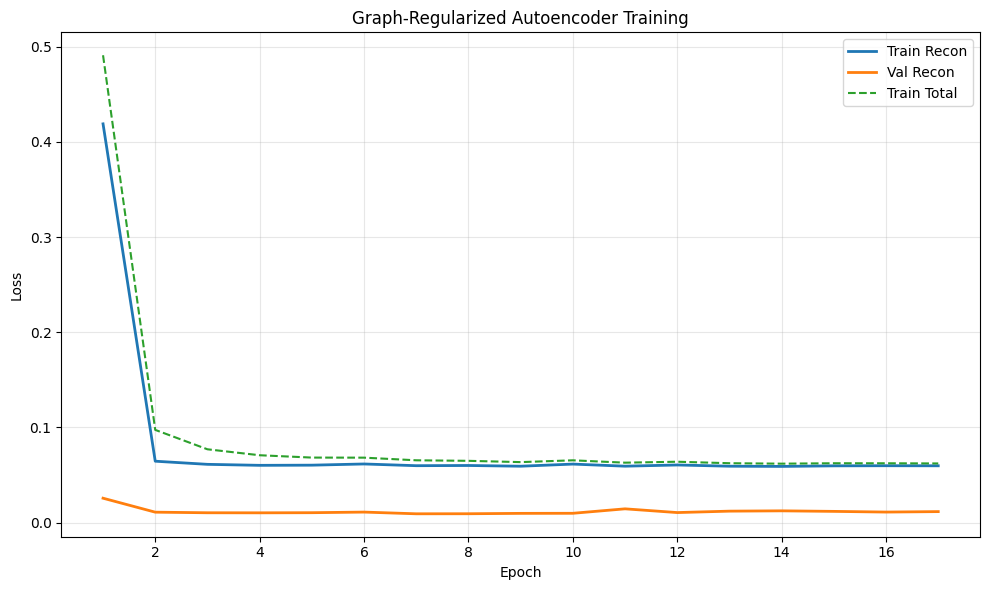

In [ ]:
# -------------------------------------------------
# Training Diagnostics Plot
# -------------------------------------------------
import matplotlib.pyplot as plt

epochs = history["epoch"]

plt.figure(figsize=(10, 6))

# Reconstruction loss
plt.plot(epochs, history["train_recon"], label="Train Recon", linewidth=2)
plt.plot(epochs, history["val_recon"], label="Val Recon", linewidth=2)

# Total loss
plt.plot(epochs, history["train_total"], label="Train Total", linestyle="--")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Graph-Regularized Autoencoder Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

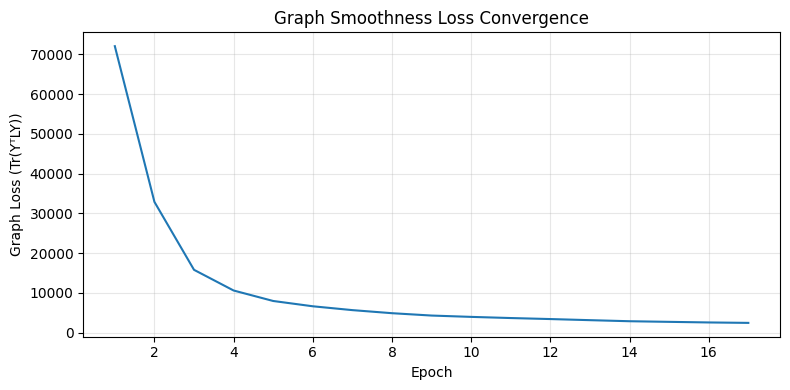

In [50]:
plt.figure(figsize=(8, 4))
plt.plot(epochs, history["train_graph"], label="Train Graph Loss")
plt.xlabel("Epoch")
plt.ylabel("Graph Loss (Tr(YᵀLY))")
plt.title("Graph Smoothness Loss Convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
np.save("Z_patients.npy", Z_graph)

print("Saved patient latent representations.")


Saved patient latent representations.


## Evaluation Pipeline (Model-Agnostic)

This section implements a reusable evaluation pipeline that accepts any latent matrix:

    Z: (n_patients, latent_dim)

and produces:
1) Geometry & organization diagnostics (label-free)
2) Clustering stability under resampling / seeds (ARI/NMI)
3) Survival association (Cox on Z, log-rank on clusters)
4) Latent robustness across restarts (cosine similarity across runs)



In [52]:
# What patient ID list do we currently have for the 941 RNA samples?

candidates = ["patient_ids_surv", "patient_ids_aligned", "patient_index_surv", "patient_index"]

for name in candidates:
    if name in globals():
        obj = globals()[name]
        try:
            print(f"{name}: type={type(obj)} | len={len(obj)} | first5={list(obj)[:5]}")
        except Exception as e:
            print(f"{name}: exists but cannot inspect ({e})")


patient_ids_aligned: type=<class 'numpy.ndarray'> | len=941 | first5=['TCGA-3C-AAAU-01A', 'TCGA-3C-AALI-01A', 'TCGA-3C-AALJ-01A', 'TCGA-3C-AALK-01A', 'TCGA-4H-AAAK-01A']
patient_index: type=<class 'list'> | len=950 | first5=['TCGA-3C-AAAU-01A', 'TCGA-3C-AALI-01A', 'TCGA-3C-AALJ-01A', 'TCGA-3C-AALK-01A', 'TCGA-4H-AAAK-01A']


### Survival data alignment

At this stage, survival information must be aligned **exactly** to the patient order
used for autoencoder training. This ensures that each latent vector corresponds
to the correct clinical outcome without ambiguity.

We treat the autoencoder patient order as authoritative and reorder survival
data accordingly.


### TCGA identifier harmonization

TCGA molecular data are indexed at the sample level (e.g., TCGA-XX-YYYY-01A),
whereas clinical and survival data are indexed at the case level
(TCGA-XX-YYYY).

To ensure correct alignment, we harmonize identifiers by reducing all
sample-level IDs to their corresponding case-level IDs prior to merging.


In [53]:
# --- Harmonize TCGA identifiers to case-level (first 12 characters) ---
survival_df = surv_df_final

# AE patient IDs → case IDs
ae_case_ids = np.array([pid[:12] for pid in patient_ids_aligned])

print("AE case IDs example:", ae_case_ids[:5])
print("Unique AE cases:", len(np.unique(ae_case_ids)))

# Survival patient IDs are already case-level
survival_df["case_id"] = survival_df["patient_id"].str[:12]

# Filter survival to AE cases
survival_filtered = survival_df[
    survival_df["case_id"].isin(ae_case_ids)
].copy()

print("Survival after filtering:", survival_filtered.shape)

# Reindex survival to match AE order
survival_aligned = (
    survival_filtered
    .set_index("case_id")
    .loc[ae_case_ids]
    .reset_index(drop=True)
)

# --- Hard checks ---
assert survival_aligned.shape[0] == len(ae_case_ids)
assert not survival_aligned[["time", "event"]].isna().any().any()

print("Survival successfully aligned at case level")
survival_aligned.head()


AE case IDs example: ['TCGA-3C-AAAU' 'TCGA-3C-AALI' 'TCGA-3C-AALJ' 'TCGA-3C-AALK'
 'TCGA-4H-AAAK']
Unique AE cases: 935
Survival after filtering: (935, 5)
Survival successfully aligned at case level


,patient_id,time,event,age_at_diagnosis
0,TCGA-3C-AAAU,4047.0,0,55
1,TCGA-3C-AALI,4005.0,0,50
2,TCGA-3C-AALJ,1474.0,0,62
3,TCGA-3C-AALK,1448.0,0,52
4,TCGA-4H-AAAK,348.0,0,50


### Latent space sanity checks (baseline autoencoder)

Before downstream evaluation, we verify that the learned latent representations
are numerically stable and non-degenerate. In particular, we assess:

- variance across latent dimensions (to detect collapsed dimensions),
- norm distribution across samples (to detect exploding or vanishing embeddings),
- basic summary statistics of the latent space.

These checks are applied consistently to all representation models evaluated
in this study.


In [54]:
import numpy as np
import pandas as pd

Z = Z_graph  # shape (n_samples, latent_dim)

print("Latent shape:", Z.shape)

# --- 1. Per-dimension variance ---
latent_var = Z.var(axis=0)

print("\nLatent variance summary:")
print(pd.Series(latent_var).describe())

num_near_zero = np.sum(latent_var < 1e-6)
print(f"Collapsed dimensions (<1e-6 variance): {num_near_zero} / {Z.shape[1]}")

# --- 2. Sample-wise L2 norm ---
latent_norm = np.linalg.norm(Z, axis=1)

print("\nLatent norm summary:")
print(pd.Series(latent_norm).describe())

# --- 3. Global statistics ---
print("\nGlobal latent statistics:")
print(f"Mean: {Z.mean():.4f}")
print(f"Std:  {Z.std():.4f}")
print(f"Min:  {Z.min():.4f}")
print(f"Max:  {Z.max():.4f}")


Latent shape: (941, 64)

Latent variance summary:
count    64.000000
mean      0.001160
std       0.000712
min       0.000238
25%       0.000627
50%       0.001025
75%       0.001482
max       0.003282
dtype: float64
Collapsed dimensions (<1e-6 variance): 0 / 64

Latent norm summary:
count    941.000000
mean       0.366982
std        0.111666
min        0.220779
25%        0.280563
50%        0.351084
75%        0.421085
max        1.354971
dtype: float64

Global latent statistics:
Mean: -0.0019
Std:  0.0479
Min:  -0.3448
Max:  0.2961


## Clustering stability on latent space (Z) — KMeans, k=5
Goal:
   - Cluster the AE latent representations directly (no PCA)
   - Evaluate stability across random seeds using ARI / NMI


Notes:
   - This is an INTERNAL evaluation: does Z produce consistent structure?
   - We are NOT claiming subtypes; we are measuring representation stability.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --- Inputs expected ---
# Z_baseline: np.ndarray (n_samples, latent_dim)

Z_baseline = Z_graph

assert isinstance(Z_baseline, np.ndarray), "Z_baseline must be a numpy array"
assert Z_baseline.ndim == 2, f"Expected Z_baseline to be 2D, got {Z_baseline.ndim}D"
n, d = Z_baseline.shape
print(f"Z shape: {Z_baseline.shape}")

# --- Config ---
K = 5
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] 
n_init = 20  # more stable KMeans solutions

# --- Run clustering across seeds ---
labels_by_seed = {}
cluster_sizes_by_seed = {}

for s in seeds:
    km = KMeans(n_clusters=K, random_state=s, n_init=n_init)
    labels = km.fit_predict(Z_baseline)
    labels_by_seed[s] = labels
    cluster_sizes_by_seed[s] = np.bincount(labels, minlength=K)

print("\nCluster sizes by seed:")
for s in seeds:
    print(f"seed={s:2d} | sizes={cluster_sizes_by_seed[s].tolist()}")

# --- Pairwise stability metrics (ARI, NMI) ---
aris = []
nmis = []

seed_list = list(labels_by_seed.keys())
for i in range(len(seed_list)):
    for j in range(i + 1, len(seed_list)):
        a = labels_by_seed[seed_list[i]]
        b = labels_by_seed[seed_list[j]]
        aris.append(adjusted_rand_score(a, b))
        nmis.append(normalized_mutual_info_score(a, b))

aris = np.array(aris)
nmis = np.array(nmis)

print("\nStability across seeds (pairwise comparisons):")
print(f"ARI | mean={aris.mean():.4f} | std={aris.std():.4f} | min={aris.min():.4f} | max={aris.max():.4f}")
print(f"NMI | mean={nmis.mean():.4f} | std={nmis.std():.4f} | min={nmis.min():.4f} | max={nmis.max():.4f}")

# -Keep one 'reference' clustering for later analyses
# We'll use seed=0 as the reference assignment (consistent, deterministic)
labels_k5_ref = labels_by_seed[0]
print("\nSaved reference labels: labels_k5_ref (seed=0)\n")

# Print stability summary
stability_summary = {
    "K": K,
    "n_samples": n,
    "latent_dim": d,
    "n_seeds": len(seeds),
    "ARI": {
        "mean": float(aris.mean()),
        "std": float(aris.std()),
        "min": float(aris.min()),
        "max": float(aris.max()),
    },
    "NMI": {
        "mean": float(nmis.mean()),
        "std": float(nmis.std()),
        "min": float(nmis.min()),
        "max": float(nmis.max()),
    },
    "cluster_sizes_by_seed": cluster_sizes_by_seed,
}

print(stability_summary)

Z shape: (941, 64)

Cluster sizes by seed:
seed= 0 | sizes=[375, 148, 173, 132, 113]
seed= 1 | sizes=[375, 148, 113, 132, 173]
seed= 2 | sizes=[132, 113, 173, 375, 148]
seed= 3 | sizes=[375, 148, 173, 132, 113]
seed= 4 | sizes=[375, 148, 173, 132, 113]
seed= 5 | sizes=[132, 173, 375, 148, 113]
seed= 6 | sizes=[173, 132, 375, 148, 113]
seed= 7 | sizes=[113, 375, 132, 173, 148]
seed= 8 | sizes=[375, 113, 132, 148, 173]
seed= 9 | sizes=[174, 375, 112, 148, 132]

Stability across seeds (pairwise comparisons):
ARI | mean=0.9997 | std=0.0007 | min=0.9983 | max=1.0000
NMI | mean=0.9992 | std=0.0017 | min=0.9958 | max=1.0000

Saved reference labels: labels_k5_ref (seed=0)

{'K': 5, 'n_samples': 941, 'latent_dim': 64, 'n_seeds': 10, 'ARI': {'mean': 0.9996569753102901, 'std': 0.0006860493794198508, 'min': 0.9982848765514504, 'max': 1.0}, 'NMI': {'mean': 0.9991577047711172, 'std': 0.001684590457765895, 'min': 0.9957885238555853, 'max': 1.0000000000000002}, 'cluster_sizes_by_seed': {0: array([375,

## Restart Stability Experiment

Goal:
- Quantify how stable the learned latent space is **across independent AE restarts** (different random seeds),
  *before* adding denoising, graph regularization, or graph encoders.

Protocol:
1) Train the same AE multiple times with different seeds (same architecture + hyperparameters).
2) For each run:
   - Extract latent embeddings Z (patients × d).
   - Cluster Z using KMeans with fixed k=5 (same clustering probe as before).
3) Measure agreement across runs using ARI and NMI.
4) Save:
   - Z for each run
   - cluster labels for each run
   - a summary table of stability metrics


In [56]:
# ============================================================
# Gene-Level Dataset for Graph-Regularized AE
# ============================================================

class GeneAutoencoderDataset(Dataset):
    """
    Dataset for gene-wise autoencoder models.

    X shape: (n_patients, n_genes, n_modalities)
    """

    def __init__(
        self,
        X: np.ndarray,
        noise_std: float = 0.0,
        mask_prob: float = 0.0,
        seed: int = 42,
        dtype=torch.float32,
    ):
        assert X.ndim == 3, "X must be (patients, genes, modalities)"

        self.X = torch.tensor(X, dtype=dtype)
        self.noise_std = noise_std
        self.mask_prob = mask_prob
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.X.shape[0]

    def _corrupt(self, x):
        """
        x shape: (n_genes, n_modalities)
        """

        x_tilde = x.clone()

        # Gaussian noise
        if self.noise_std > 0:
            noise = torch.tensor(
                self.rng.normal(0.0, self.noise_std, size=x.shape),
                dtype=x.dtype,
            )
            x_tilde = x_tilde + noise

        # Feature masking
        if self.mask_prob > 0:
            mask = torch.tensor(
                self.rng.uniform(size=x.shape) > self.mask_prob,
                dtype=x.dtype,
            )
            x_tilde = x_tilde * mask

        return x_tilde

    def __getitem__(self, idx):
        x = self.X[idx]              # (genes, modalities)
        x_tilde = self._corrupt(x)
        return x_tilde, x

In [57]:
print(GeneWiseDAE.__init__.__code__.co_varnames)

('self', 'p_in', 'latent_dim', 'h1', 'h2')


In [58]:
import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ============================================================
# 0) Reproducibility helper
# ============================================================
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ============================================================
# 2G) Train Graph-Regularized AE + Extract Latent
# ============================================================

def train_graph_ae_and_extract_Z(
    X_gene: np.ndarray,
    L_sparse_torch: torch.Tensor,
    seed: int,
    latent_dim: int = 64,
    batch_size: int = 16,
    lr: float = 1e-3,
    weight_decay: float = 0.0,
    epochs: int = 30,
    noise_std: float = 0.0,
    mask_prob: float = 0.0,
    lambda_graph: float = 1e-4,
    device: str = None,
):

    set_seed(seed)

    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------
    train_dataset = GeneAutoencoderDataset(
        X=X_gene,
        noise_std=noise_std,
        mask_prob=mask_prob,
        seed=seed
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------
    model = GeneWiseDAE(
    p_in=X_gene.shape[2],
    latent_dim=latent_dim
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    recon_criterion = nn.MSELoss()

    L_sparse_torch = L_sparse_torch.to(device)

    loss_history = []

    # ========================================================
    # TRAINING
    # ========================================================
    model.train()

    for ep in range(1, epochs + 1):

        epoch_losses = []

        for x_tilde, x in train_loader:

            x_tilde = x_tilde.to(device)
            x = x.to(device)

            optimizer.zero_grad()

            x_hat, Y, z_patient = model(x_tilde)

            # Reconstruction
            recon_loss = recon_criterion(x_hat, x)

            # Graph loss
            graph_loss = 0.0
            if lambda_graph > 0:
                # batch computation
                for b in range(Y.shape[0]):
                    Y_b = Y[b]  # (G, d)
                    graph_loss += torch.trace(
                        Y_b.T @ torch.sparse.mm(L_sparse_torch, Y_b)
                    )
                graph_loss = graph_loss / Y.shape[0]

            total_loss = recon_loss + lambda_graph * graph_loss

            total_loss.backward()
            optimizer.step()

            epoch_losses.append(total_loss.item())

        epoch_loss = float(np.mean(epoch_losses))
        loss_history.append(epoch_loss)

        if ep in [1, 5, 10, 20, epochs]:
            print(
                f"[seed={seed}] epoch {ep:03d} | "
                f"noise={noise_std} mask={mask_prob} "
                f"lambda={lambda_graph} | "
                f"total={epoch_loss:.4f}"
            )

    # ========================================================
    # LATENT EXTRACTION (CLEAN INPUT)
    # ========================================================
    model.eval()

    clean_dataset = GeneAutoencoderDataset(
        X=X_gene,
        noise_std=0.0,
        mask_prob=0.0,
        seed=seed
    )

    clean_loader = DataLoader(
        clean_dataset,
        batch_size=32,
        shuffle=False
    )

    Z_list = []

    with torch.no_grad():
        for x_clean, _ in clean_loader:
            x_clean = x_clean.to(device)
            _, _, z_patient = model(x_clean)
            Z_list.append(z_patient.cpu().numpy())

    Z = np.vstack(Z_list)

    return Z, loss_history

# ============================================================
# 3G) Restart Stability Experiment (Graph Version)
# ============================================================

def restart_stability_experiment_graph(
    X_gene: np.ndarray,
    L_sparse_torch: torch.Tensor,
    seeds=(0, 1, 2, 3, 4),
    k=5,
    noise_std=0.0,
    mask_prob=0.0,
    lambda_graph=1e-4,
    **train_kwargs,
):

    Z_runs = {}
    labels_runs = {}
    loss_curves = {}

    print("\n=== Graph-Regularized Restarts ===")
    print(
        f"noise={noise_std}, mask={mask_prob}, "
        f"lambda={lambda_graph}\n"
    )

    for s in seeds:

        Z, losses = train_graph_ae_and_extract_Z(
            X_gene=X_gene,
            L_sparse_torch=L_sparse_torch,
            seed=s,
            noise_std=noise_std,
            mask_prob=mask_prob,
            lambda_graph=lambda_graph,
            **train_kwargs,
        )

        Z_runs[s] = Z
        loss_curves[s] = losses

        km = KMeans(n_clusters=k, n_init=20, random_state=0)
        labels = km.fit_predict(Z)

        labels_runs[s] = labels

        sizes = np.bincount(labels)
        print(f"[seed={s}] Z shape={Z.shape} | cluster sizes={sizes.tolist()}")

    # --------------------------------------------------------
    # Pairwise stability
    # --------------------------------------------------------
    rows = []
    seed_list = list(seeds)

    for i in range(len(seed_list)):
        for j in range(i + 1, len(seed_list)):
            s1, s2 = seed_list[i], seed_list[j]
            ari = adjusted_rand_score(labels_runs[s1], labels_runs[s2])
            nmi = normalized_mutual_info_score(labels_runs[s1], labels_runs[s2])
            rows.append({
                "seed_a": s1,
                "seed_b": s2,
                "ARI": ari,
                "NMI": nmi
            })

    stab_df = pd.DataFrame(rows)

    print("\n=== Restart Stability Summary ===")
    print(stab_df.describe())

    return stab_df, Z_runs, loss_curves, labels_runs


In [59]:
stab_df_graph, Z_runs_graph, loss_curves_graph, labels_runs_graph = restart_stability_experiment_graph(
    X_gene=X_gene,
    L_sparse_torch=L_torch,
    seeds=(0,1,2,3,4),
    k=5,
    epochs=20,
    lr=1e-3,
    batch_size=16,
    latent_dim=64,
    noise_std=0.3,
    mask_prob=0,
    lambda_graph=lambda_graph
)


=== Graph-Regularized Restarts ===
noise=0.3, mask=0, lambda=1e-06

[seed=0] epoch 001 | noise=0.3 mask=0 lambda=1e-06 | total=0.4365
[seed=0] epoch 005 | noise=0.3 mask=0 lambda=1e-06 | total=0.0676
[seed=0] epoch 010 | noise=0.3 mask=0 lambda=1e-06 | total=0.0625
[seed=0] epoch 020 | noise=0.3 mask=0 lambda=1e-06 | total=0.0612
[seed=0] Z shape=(941, 64) | cluster sizes=[111, 375, 132, 148, 175]
[seed=1] epoch 001 | noise=0.3 mask=0 lambda=1e-06 | total=0.4743
[seed=1] epoch 005 | noise=0.3 mask=0 lambda=1e-06 | total=0.0668
[seed=1] epoch 010 | noise=0.3 mask=0 lambda=1e-06 | total=0.0634
[seed=1] epoch 020 | noise=0.3 mask=0 lambda=1e-06 | total=0.0604
[seed=1] Z shape=(941, 64) | cluster sizes=[375, 145, 135, 104, 182]
[seed=2] epoch 001 | noise=0.3 mask=0 lambda=1e-06 | total=0.4814
[seed=2] epoch 005 | noise=0.3 mask=0 lambda=1e-06 | total=0.0675
[seed=2] epoch 010 | noise=0.3 mask=0 lambda=1e-06 | total=0.0629
[seed=2] epoch 020 | noise=0.3 mask=0 lambda=1e-06 | total=0.0615
[

#### Save all 5 restart seeds, then sweep k (no retraining required)

The retraining above already produces `Z_runs` (all 5 seeds). Saving it now unlocks a free k-sweep, since k only
enters at the clustering step, not during training.


In [60]:

np.savez("Z_runs_graph_all_seeds.npz", **{str(k): v for k, v in Z_runs_graph.items()})
print("Saved all 5 seeds' embeddings.")


Saved all 5 seeds' embeddings.


In [61]:

# -------------------------------------------------
# Reusable k-sweep: no retraining needed once Z_runs (all 5 seeds) is available --
# k only enters at the clustering step, not during training.
# -------------------------------------------------
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def restart_ari_vs_k(Z_runs_dict, k_values=range(2, 9), label=""):
    seeds = sorted(Z_runs_dict.keys())
    results = []
    for k in k_values:
        labels_by_seed = {s: KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(Z_runs_dict[s])
                           for s in seeds}
        aris, nmis = [], []
        for i in range(len(seeds)):
            for j in range(i + 1, len(seeds)):
                aris.append(adjusted_rand_score(labels_by_seed[seeds[i]], labels_by_seed[seeds[j]]))
                nmis.append(normalized_mutual_info_score(labels_by_seed[seeds[i]], labels_by_seed[seeds[j]]))
        results.append({"k": k, "mean_ARI": np.mean(aris), "std_ARI": np.std(aris),
                         "mean_NMI": np.mean(nmis), "std_NMI": np.std(nmis)})
    df = pd.DataFrame(results)
    print(f"\\n=== Restart ARI/NMI vs. k -- {label} ===")
    print(df.to_string(index=False))
    return df


In [62]:

k_sweep_graph_df = restart_ari_vs_k(Z_runs_graph, label="GR-DAE (real graph, selected lambda)")


\n=== Restart ARI/NMI vs. k -- GR-DAE (real graph, selected lambda) ===
 k  mean_ARI  std_ARI  mean_NMI  std_NMI
 2  0.986437 0.006489  0.969135 0.013857
 3  0.970088 0.014404  0.949796 0.022815
 4  0.983542 0.006338  0.972955 0.008546
 5  0.982735 0.007923  0.970189 0.012648
 6  0.985211 0.006326  0.972984 0.010729
 7  0.962366 0.013981  0.942454 0.017559
 8  0.894429 0.053973  0.902748 0.029785


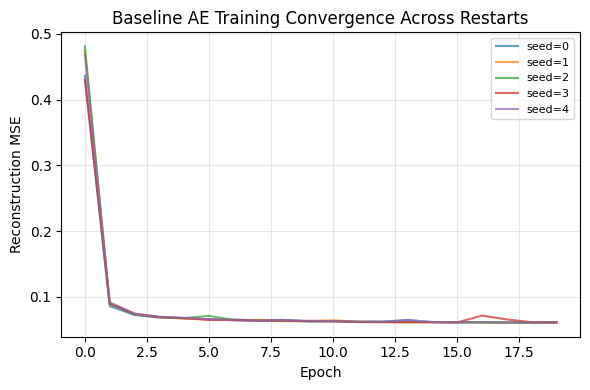

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
for s, losses in loss_curves_graph.items():
    plt.plot(losses, alpha=0.7, label=f"seed={s}")

plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Training Convergence Across Restarts")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


In [64]:
final_losses = {s: losses[-1] for s, losses in loss_curves_graph.items()}

print("Final reconstruction loss by seed:")
for s, l in final_losses.items():
    print(f"seed={s}: {l:.4f}")

print(
    "\nFinal loss mean ± std:",
    np.mean(list(final_losses.values())),
    "±",
    np.std(list(final_losses.values()))
)


Final reconstruction loss by seed:
seed=0: 0.0612
seed=1: 0.0604
seed=2: 0.0615
seed=3: 0.0612
seed=4: 0.0612

Final loss mean ± std: 0.06110713533678297 ± 0.0003655506580666143


## Representation-level stability across AE restarts (geometry-based)

To evaluate whether the learned latent space is stable across random restarts, we compare the *geometry* of the embedding space rather than relying only on clustering labels.

For each trained model restart, we compute the patient–patient distance matrix in latent space (Euclidean distance on `Z`). We then quantify stability by measuring the correlation between distance matrices across restarts (using Spearman correlation on the upper-triangular entries).

- It is independent of clustering choices (no dependency on KMeans or `k`).
- It measures whether *relative patient relationships* are preserved across restarts, consistent with our thesis focus on representation geometry and stability.


In [65]:
print("Type of Z_runs:", type(Z_runs_graph))
print("Length of Z_runs:", len(Z_runs_graph))

print("\nInspect first element:")
print("Type:", type(Z_runs_graph[0]))

if hasattr(Z_runs_graph[0], "shape"):
    print("Shape:", Z_runs_graph[0].shape)
else:
    print("No .shape attribute")

# If torch tensor
try:
    import torch
    print("Is torch tensor:", isinstance(Z_runs_graph[0], torch.Tensor))
except:
    pass


Type of Z_runs: <class 'dict'>
Length of Z_runs: 5

Inspect first element:
Type: <class 'numpy.ndarray'>
Shape: (941, 64)
Is torch tensor: False


In [66]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr, pearsonr

In [67]:
def flatten_distance_matrix(Z, metric="euclidean"):
    """
    Compute the condensed pairwise distance vector (upper triangle)
    for patient embeddings Z.

    Parameters
    ----------
    Z : np.ndarray, shape (n_patients, latent_dim)
    metric : str
        Distance metric passed to scipy.spatial.distance.pdist

    Returns
    -------
    dists : np.ndarray, shape (n_patients * (n_patients - 1) / 2,)
    """
    assert isinstance(Z, np.ndarray), "Z must be a numpy array"
    assert Z.ndim == 2, "Z must be 2D: (patients, latent_dim)"
    return pdist(Z, metric=metric)


In [68]:
def geometry_stability(Z_runs, metric="euclidean"):
    """
    Evaluate geometry stability across multiple AE restarts by correlating
    patient–patient distance matrices.

    Parameters
    ----------
    Z_runs : list of np.ndarray
        Each element is a latent matrix of shape (n_patients, latent_dim)
        from an independent AE restart.
    metric : str
        Distance metric (default: 'euclidean')

    Returns
    -------
    stab_df : pd.DataFrame
        Pairwise geometry stability statistics across runs.
    """

    # ---------- sanity checks ----------
    assert isinstance(Z_runs, (list, tuple)), "Z_runs must be a list of arrays"
    n_runs = len(Z_runs)
    assert n_runs >= 2, "Need at least two runs for stability analysis"

    n_patients = Z_runs[0].shape[0]
    for i, Z in enumerate(Z_runs):
        assert Z.shape[0] == n_patients, f"Run {i} has mismatched patient count"

    # ---------- compute distance vectors ----------
    dist_vecs = [
        flatten_distance_matrix(Z, metric=metric)
        for Z in Z_runs
    ]

    # ---------- compare geometries ----------
    rows = []
    for (i, dv_i), (j, dv_j) in combinations(enumerate(dist_vecs), 2):
        rows.append({
            "run_a": i,
            "run_b": j,
            "spearman_dist_corr": spearmanr(dv_i, dv_j).correlation,
            "pearson_dist_corr": pearsonr(dv_i, dv_j)[0]
        })

    stab_df = pd.DataFrame(rows)

    # ---------- summary ----------
    print("=== Geometry stability across AE restarts ===")
    print(stab_df[["spearman_dist_corr", "pearson_dist_corr"]].describe())

    return stab_df


In [69]:
# Convert dict → ordered list (by seed)
Z_runs_list = [Z_runs_graph[k] for k in sorted(Z_runs_graph.keys())]

# Geometry stability
geom_stab_df = geometry_stability(
    Z_runs_list,
    metric="euclidean"   # aligned with MSE-trained AE
)

geom_stab_df.head()


=== Geometry stability across AE restarts ===
       spearman_dist_corr  pearson_dist_corr
count           10.000000          10.000000
mean             0.997441           0.996542
std              0.000891           0.001800
min              0.996346           0.993856
25%              0.996736           0.994977
50%              0.997267           0.996976
75%              0.997875           0.997838
max              0.998973           0.998725


,run_a,run_b,spearman_dist_corr,pearson_dist_corr
0,0,1,0.996951,0.996586
1,0,2,0.997541,0.997367
2,0,3,0.996992,0.994833
3,0,4,0.997894,0.997817
4,1,2,0.998973,0.998725


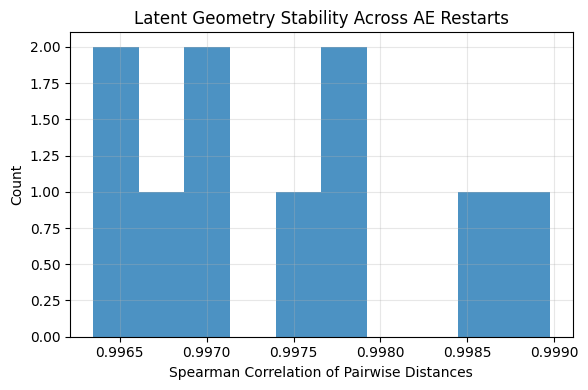

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(geom_stab_df["spearman_dist_corr"], bins=10, alpha=0.8)
plt.xlabel("Spearman Correlation of Pairwise Distances")
plt.ylabel("Count")
plt.title("Latent Geometry Stability Across AE Restarts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


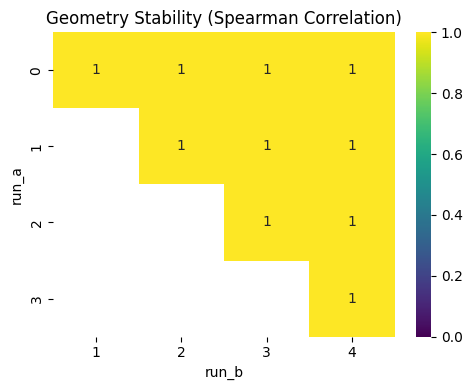

In [71]:
import seaborn as sns

pivot = geom_stab_df.pivot(
    index="run_a", columns="run_b", values="spearman_dist_corr"
)

plt.figure(figsize=(5, 4))
sns.heatmap(pivot, annot=True, cmap="viridis", vmin=0, vmax=1)
plt.title("Geometry Stability (Spearman Correlation)")
plt.tight_layout()
plt.show()


## Latent Geometry Snapshot

This step provides a geometry-focused characterization of the learned latent space $Z$ for the baseline autoencoder.
The goal is **descriptive**, not evaluative: we summarize how variance and structure are distributed in the latent
representation, without introducing clustering, labels, or downstream tasks.

Specifically, we analyze:

1. **Principal component structure (PCA)**  
   PCA is used *only* as a visualization and diagnostic tool to assess variance concentration and global organization.
   It is **not** used for clustering or evaluation.

2. **Variance per latent dimension**  
   We examine how information is distributed across the learned latent dimensions, checking for collapsed or
   degenerate dimensions.

3. **Latent norm distribution**  
   The distribution of $\|z_i\|_2$ across patients provides insight into scale consistency and representation spread.

These analyses help verify that the autoencoder learns a non-degenerate, structured latent space suitable for
downstream post-hoc evaluation.


Z_baseline shape: (941, 64)

PCA variance summary:
PC01: var=0.5248 | cumulative=0.5248
PC02: var=0.2792 | cumulative=0.8040
PC03: var=0.1119 | cumulative=0.9160
PC04: var=0.0495 | cumulative=0.9655
PC05: var=0.0192 | cumulative=0.9847
PC06: var=0.0056 | cumulative=0.9903
PC07: var=0.0035 | cumulative=0.9939
PC08: var=0.0020 | cumulative=0.9959
PC09: var=0.0014 | cumulative=0.9973
PC10: var=0.0006 | cumulative=0.9979
PC11: var=0.0005 | cumulative=0.9984
PC12: var=0.0003 | cumulative=0.9988
PC13: var=0.0003 | cumulative=0.9991
PC14: var=0.0002 | cumulative=0.9992
PC15: var=0.0002 | cumulative=0.9994
PC16: var=0.0001 | cumulative=0.9996
PC17: var=0.0001 | cumulative=0.9997
PC18: var=0.0001 | cumulative=0.9997
PC19: var=0.0001 | cumulative=0.9998
PC20: var=0.0000 | cumulative=0.9998


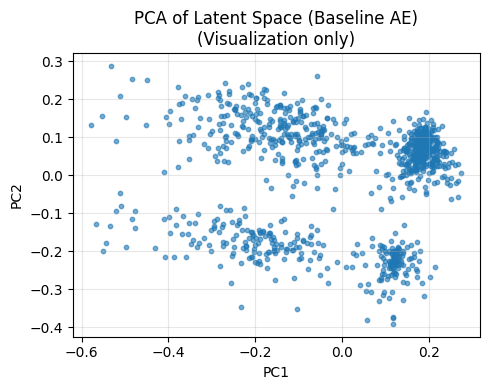

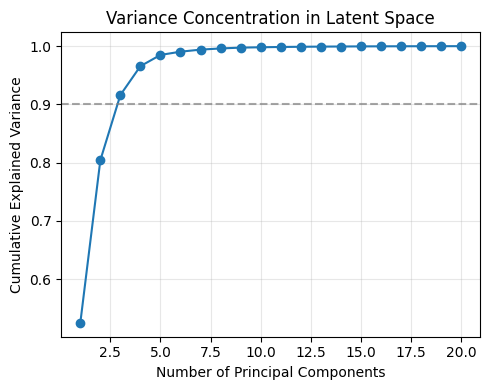


Latent dimension variance summary:
count    64.000000
mean      0.001160
std       0.000712
min       0.000238
25%       0.000627
50%       0.001025
75%       0.001482
max       0.003282
dtype: float64


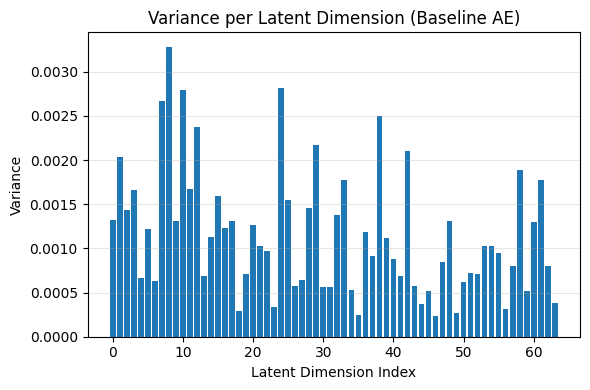


Latent norm summary:
count    941.000000
mean       0.366982
std        0.111666
min        0.220779
25%        0.280563
50%        0.351084
75%        0.421085
max        1.354971
dtype: float64


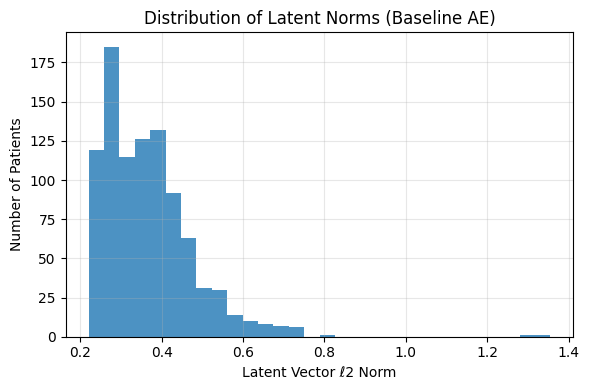

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# --------------------------
# Sanity checks
# --------------------------
assert isinstance(Z_baseline, np.ndarray), "Z_baseline must be a numpy array"
assert Z_baseline.ndim == 2, "Z_baseline must be 2D (patients × latent_dim)"

n_patients, latent_dim = Z_baseline.shape
print(f"Z_baseline shape: {Z_baseline.shape}")

# ============================================================
# 1) PCA (visualization + variance concentration)
# ============================================================
pca = PCA(n_components=min(latent_dim, 20), random_state=0)
Z_pca = pca.fit_transform(Z_baseline)

explained_var = pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

# ---- Print summary ----
print("\nPCA variance summary:")
for i, (v, cv) in enumerate(zip(explained_var, cum_explained_var), start=1):
    print(f"PC{i:02d}: var={v:.4f} | cumulative={cv:.4f}")

# ---- PCA scatter (first two PCs) ----
plt.figure(figsize=(5, 4))
plt.scatter(Z_pca[:, 0], Z_pca[:, 1], s=10, alpha=0.6)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Latent Space \n(Visualization only)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Cumulative variance plot ----
plt.figure(figsize=(5, 4))
plt.plot(range(1, len(cum_explained_var) + 1), cum_explained_var, marker="o")
plt.axhline(0.9, linestyle="--", color="gray", alpha=0.7)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Variance Concentration in Latent Space")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 2) Variance per latent dimension
# ============================================================
latent_var = Z_baseline.var(axis=0)

print("\nLatent dimension variance summary:")
print(pd.Series(latent_var).describe())

plt.figure(figsize=(6, 4))
plt.bar(range(latent_dim), latent_var)
plt.xlabel("Latent Dimension Index")
plt.ylabel("Variance")
plt.title("Variance per Latent Dimension")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3) Latent norm distribution
# ============================================================
latent_norms = np.linalg.norm(Z_baseline, axis=1)

print("\nLatent norm summary:")
print(pd.Series(latent_norms).describe())

plt.figure(figsize=(6, 4))
plt.hist(latent_norms, bins=30, alpha=0.8)
plt.xlabel("Latent Vector ℓ2 Norm")
plt.ylabel("Number of Patients")
plt.title("Distribution of Latent Norms")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Prepare reference latent (seed=0) for survival analysis
- Convert AE sample-level Z (941) -> case-level Z (935)
- Align to survival_aligned (case-level)

In [ ]:
# ============================================================
# STEP: Prepare reference latent (seed=0) for survival analysis
#       - Convert AE sample-level Z (941) -> case-level Z (935)
#       - Align to survival_aligned (case-level)
#       - Fix duplicated survival case IDs (common TCGA issue)
# ============================================================

import numpy as np
import pandas as pd

# --------------------------
# 0) Load latent representations
# --------------------------
Z_ref = np.load("Z_patients.npy")   # shape: (941, 64)
print("Loaded Z_ref:", Z_ref.shape)

# --------------------------
# 0b) Recover patient IDs used by AE
# --------------------------
# OPTION A (preferred): patient_ids_aligned already exists in memory
if "patient_ids_aligned" in globals():
    patient_ids = np.asarray(patient_ids_aligned)
    print("Using patient_ids_aligned from memory.")

# OPTION B: stored inside AE dataset
elif "ae_dataset" in globals() and hasattr(ae_dataset, "patient_ids"):
    patient_ids = np.asarray(ae_dataset.patient_ids)
    print("Using patient IDs from ae_dataset.")

else:
    raise RuntimeError(
        "Patient IDs not found. "
        "They must come from the AE dataset or alignment step."
    )

assert len(patient_ids) == Z_ref.shape[0], "Patient ID / Z mismatch"
print("Loaded patient_ids:", patient_ids.shape, "| example:", patient_ids[:5])

# --------------------------
# 1) Convert sample IDs -> case IDs
#    TCGA case ID = first 12 characters (e.g., TCGA-XX-YYYY)
# --------------------------
case_ids = np.array([pid[:12] for pid in patient_ids])
print("\nUnique case IDs in AE latents:", len(np.unique(case_ids)))

# --------------------------
# 2) Aggregate Z to case-level
#    If multiple samples exist for same case, take mean embedding
# --------------------------
Z_df = pd.DataFrame(Z_ref)
Z_df["case_id"] = case_ids

Z_case_df = (
    Z_df
    .groupby("case_id", sort=False)
    .mean()  # numeric-only by construction here
)

print("\nZ_case_df shape (case-level):", Z_case_df.shape)
print("Example case IDs:", Z_case_df.index[:5].tolist())
print("Z_case_df index unique:", Z_case_df.index.is_unique)

# --------------------------
# 3) Prepare survival at case-level + FIX duplicates
# --------------------------
# Ensure survival is indexed by case_id
if "patient_id" in survival_aligned.columns:
    survival_case = survival_aligned.set_index("patient_id").copy()
else:
    survival_case = survival_aligned.copy()

# Diagnose + fix duplicates (TCGA can have repeated case rows)
dup_counts = survival_case.index.value_counts()
n_dup_cases = int((dup_counts > 1).sum())
print("\nSurvival index unique BEFORE:", survival_case.index.is_unique)
print("Duplicated survival case IDs:", n_dup_cases)

if n_dup_cases > 0:
    # Since survival_aligned is already aggregated (time/event per case),
    # duplicates should be identical; keep the first occurrence per case.
    survival_case = survival_case.groupby(survival_case.index).first()
    print("Deduplicated survival_case by keeping first row per case.")

print("Survival index unique AFTER:", survival_case.index.is_unique)
print("Survival_case shape:", survival_case.shape)

# --------------------------
# 4) Strict alignment (case-level)
# --------------------------
common_cases = survival_case.index.intersection(Z_case_df.index)

print("\nLatent cases:", Z_case_df.shape[0])
print("Survival cases:", survival_case.shape[0])
print("Common cases:", len(common_cases))

# Reindex BOTH to the same ordered index (defensible + reproducible)
common_cases = common_cases.sort_values()

Z_case = Z_case_df.loc[common_cases].to_numpy()
survival_case = survival_case.loc[common_cases]

# --------------------------
# 5) Final sanity checks
# --------------------------
print("\nAfter alignment:")
print("Z_case shape:", Z_case.shape)
print("survival_case shape:", survival_case.shape)

assert survival_case.index.is_unique, "survival_case still has duplicate case IDs"
assert Z_case.shape[0] == survival_case.shape[0], "Row mismatch after alignment"
assert not np.isnan(Z_case).any(), "NaNs in Z_case"
assert survival_case[["time", "event"]].isna().sum().sum() == 0, "Missing survival data"

print("\nEvent distribution:")
print(survival_case["event"].value_counts())

print("\nTime summary:")
print(survival_case["time"].describe())

# Preview: add latent norm for quick sanity check
preview = survival_case.copy()
preview["latent_norm"] = np.linalg.norm(Z_case, axis=1)

print("\nPreview (survival + latent_norm):")
display(preview.head())


Loaded Z_ref: (941, 64)
Using patient_ids_aligned from memory.
Loaded patient_ids: (941,) | example: ['TCGA-3C-AAAU-01A' 'TCGA-3C-AALI-01A' 'TCGA-3C-AALJ-01A'
 'TCGA-3C-AALK-01A' 'TCGA-4H-AAAK-01A']

Unique case IDs in AE latents: 935

Z_case_df shape (case-level): (935, 64)
Example case IDs: ['TCGA-3C-AAAU', 'TCGA-3C-AALI', 'TCGA-3C-AALJ', 'TCGA-3C-AALK', 'TCGA-4H-AAAK']
Z_case_df index unique: True

Survival index unique BEFORE: False
Duplicated survival case IDs: 6
Deduplicated survival_case by keeping first row per case.
Survival index unique AFTER: True
Survival_case shape: (935, 3)

Latent cases: 935
Survival cases: 935
Common cases: 935

After alignment:
Z_case shape: (935, 64)
survival_case shape: (935, 3)

Event distribution:
event
0    811
1    124
Name: count, dtype: int64

Time summary:
count     935.000000
mean     1227.259893
std      1211.814895
min         0.000000
25%       436.000000
50%       795.000000
75%      1667.500000
max      8605.000000
Name: time, dtype: flo

,time,event,age_at_diagnosis,latent_norm
TCGA-3C-AAAU,4047.0,0,55,0.244827
TCGA-3C-AALI,4005.0,0,50,0.339174
TCGA-3C-AALJ,1474.0,0,62,0.395507
TCGA-3C-AALK,1448.0,0,52,0.258171
TCGA-4H-AAAK,348.0,0,50,0.390769


## Survival analysis setup sanity checks
Inputs expected in memory from previous cell:

* Z_case: np.ndarray (935, 64)
* survival_case: pd.DataFrame indexed by case_id with cols:
time, event, age_at_diagnosis

In [74]:
import numpy as np
import pandas as pd

print("Z_case:", Z_case.shape, Z_case.dtype)
print("survival_case:", survival_case.shape)
print("survival_case columns:", survival_case.columns.tolist())
print("Index unique:", survival_case.index.is_unique)

assert Z_case.shape[0] == survival_case.shape[0]
assert "time" in survival_case.columns and "event" in survival_case.columns
assert (survival_case["time"] >= 0).all(), "Negative survival times found"
assert set(survival_case["event"].unique()).issubset({0,1}), "Event must be 0/1"

print("\nEvent counts:\n", survival_case["event"].value_counts())
print("\nTime summary:\n", survival_case["time"].describe())


Z_case: (935, 64) float32
survival_case: (935, 3)
survival_case columns: ['time', 'event', 'age_at_diagnosis']
Index unique: True

Event counts:
 event
0    811
1    124
Name: count, dtype: int64

Time summary:
 count     935.000000
mean     1227.259893
std      1211.814895
min         0.000000
25%       436.000000
50%       795.000000
75%      1667.500000
max      8605.000000
Name: time, dtype: float64


## Post-hoc Survival Association Analysis

This analysis evaluates whether the learned latent representations are
*associated* with patient survival outcomes. Survival labels are **not**
used during training, model selection, or representation learning.

The goal is not survival prediction, but to assess whether the unsupervised
latent space captures clinically relevant variation.


## Cox proportional hazards model on latent dimensions
- Model A: latent dims only
- Model B: latent dims + age_at_diagnosis (recommended)

Outputs:
- concordance index (C-index)
- global significance via likelihood ratio test

In [75]:
!pip -q install lifelines

from lifelines import CoxPHFitter

# Build Cox dataframe
Z_cols = [f"z{i}" for i in range(Z_case.shape[1])]
cox_df = pd.DataFrame(Z_case, index=survival_case.index, columns=Z_cols)
cox_df["time"] = survival_case["time"].values
cox_df["event"] = survival_case["event"].values

# Optional covariate
use_age = "age_at_diagnosis" in survival_case.columns
if use_age:
    cox_df["age_at_diagnosis"] = survival_case["age_at_diagnosis"].values

print("Cox DF shape:", cox_df.shape)
display(cox_df.head())

# ---- Model A: latent only ----
cph_latent = CoxPHFitter(penalizer=1e-2)  # small L2 stabilizes high-dim Cox
cph_latent.fit(cox_df[["time","event"] + Z_cols], duration_col="time", event_col="event")

print("\n=== Cox Model A (latent only) ===")
print("C-index:", cph_latent.concordance_index_)
print("Global LRT p-value:", cph_latent.log_likelihood_ratio_test().p_value)

# ---- Model B: latent + age ----
if use_age:
    cph_latent_age = CoxPHFitter(penalizer=1e-2)
    cph_latent_age.fit(
        cox_df[["time","event","age_at_diagnosis"] + Z_cols],
        duration_col="time",
        event_col="event"
    )
    print("\n=== Cox Model B (latent + age) ===")
    print("C-index:", cph_latent_age.concordance_index_)
    print("Global LRT p-value:", cph_latent_age.log_likelihood_ratio_test().p_value)
else:
    print("\n(age_at_diagnosis not available — skipping Model B)")


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 2.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 8.0 MB/s eta 0:00:00
Cox DF shape: (935, 67)


,z0,z1,z2,z3,z4,z5,z6,z7,z8,z9,...,z57,z58,z59,z60,z61,z62,z63,time,event,age_at_diagnosis
TCGA-3C-AAAU,-0.000682,0.012836,-0.030557,-0.001663,-0.036610,-0.024407,0.016666,0.029444,0.015093,-0.009391,...,-0.043173,-0.036294,0.006880,-0.004156,0.050549,0.002141,-0.010124,4047.0,0,55
TCGA-3C-AALI,-0.001278,0.025389,-0.021839,0.028785,-0.055607,-0.017078,0.048698,0.016390,-0.027646,-0.029135,...,-0.070256,-0.043242,0.037513,0.004229,0.056847,0.001514,-0.025013,4005.0,0,50
TCGA-3C-AALJ,0.005414,0.034849,0.026787,0.062785,-0.032472,0.011333,0.057276,-0.046242,-0.048059,-0.063710,...,-0.067267,-0.098678,0.036739,-0.013949,0.076690,-0.003976,-0.015777,1474.0,0,62
TCGA-3C-AALK,0.037205,-0.010988,-0.046327,-0.019653,-0.019241,-0.022060,0.011805,0.055659,0.052919,-0.051380,...,-0.014687,-0.014866,0.017266,0.008205,0.025552,0.011833,-0.029020,1448.0,0,52
TCGA-4H-AAAK,-0.032914,0.033189,0.032492,0.052992,-0.048904,0.022817,0.055979,-0.056930,-0.067876,-0.025362,...,-0.063187,-0.102766,0.021670,-0.007941,0.062046,-0.004109,0.008924,348.0,0,50



=== Cox Model A (latent only) ===
C-index: 0.6420425251087876
Global LRT p-value: 0.9999999999866195

=== Cox Model B (latent + age) ===
C-index: 0.7052939842026027
Global LRT p-value: 0.9905830016339047


In [76]:
from lifelines.utils import concordance_index
import numpy as np

def bootstrap_cindex(cph, df, n_boot=200, seed=0):
    rng = np.random.default_rng(seed)
    cidxs = []

    for _ in range(n_boot):
        sample_idx = rng.choice(df.index, size=len(df), replace=True)
        df_boot = df.loc[sample_idx].reset_index(drop=True)

        preds = -cph.predict_partial_hazard(df_boot)
        cidx = concordance_index(
            df_boot["time"], preds, df_boot["event"]
        )
        cidxs.append(cidx)

    return np.percentile(cidxs, [2.5, 50, 97.5])


ci_latent = bootstrap_cindex(
    cph_latent,
    cox_df[["time","event"] + Z_cols]
)

print("C-index (latent only) 95% CI:", ci_latent)


C-index (latent only) 95% CI: [0.58410666 0.64106899 0.69077692]


## Log-rank survival difference across clusters
- Cluster case-level Z_case
- Run multigroup log-rank

In [77]:
from sklearn.cluster import KMeans
from lifelines.statistics import multivariate_logrank_test

k = 5
seed = 0

kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
labels = kmeans.fit_predict(Z_case)

surv_tmp = survival_case.copy()
surv_tmp["cluster"] = labels

print("Cluster sizes:", surv_tmp["cluster"].value_counts().sort_index().to_dict())

# Multigroup log-rank (overall test)
lr = multivariate_logrank_test(
    event_durations=surv_tmp["time"],
    groups=surv_tmp["cluster"],
    event_observed=surv_tmp["event"]
)

print("\n=== Multigroup log-rank test ===")
print("Test statistic:", lr.test_statistic)
print("p-value:", lr.p_value)


Cluster sizes: {0: 369, 1: 174, 2: 148, 3: 132, 4: 112}

=== Multigroup log-rank test ===
Test statistic: 3.1775495643238663
p-value: 0.5285646914151929


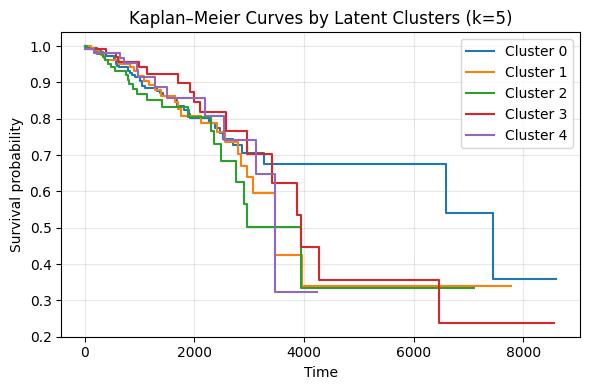

In [78]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

# Recreate surv_tmp safely
k = 5
seed = 0

kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
labels = kmeans.fit_predict(Z_case)

surv_tmp = survival_case.copy()
surv_tmp["cluster"] = labels

# Plot KM curves
plt.figure(figsize=(6, 4))
kmf = KaplanMeierFitter()

for c in sorted(surv_tmp["cluster"].unique()):
    mask = surv_tmp["cluster"] == c
    kmf.fit(
        durations=surv_tmp.loc[mask, "time"],
        event_observed=surv_tmp.loc[mask, "event"],
        label=f"Cluster {c}"
    )
    kmf.plot(ci_show=False)

plt.title("Kaplan–Meier Curves by Latent Clusters (k=5)")
plt.xlabel("Time")
plt.ylabel("Survival probability")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## PAM50 survival as a reference baseline

In [ ]:
# ============================================================
# Prepare PAM50 labels (case-level) for survival
# ============================================================

# PAM50 labels came from the multi-omics dataframe
# and were not used during AE training.

# Recover PAM50 labels from original dataframe
pam50_df = (
    df[["patient_id", "PAM50_subtype"]]
    .copy()
)

# Convert sample ID → case ID
pam50_df["case_id"] = pam50_df["patient_id"].str[:12]

# Deduplicate at case level (same logic as survival)
pam50_case = (
    pam50_df
    .dropna(subset=["PAM50_subtype"])
    .groupby("case_id", sort=False)
    .first()
)

print("PAM50 cases:", pam50_case.shape)
print("Example PAM50 labels:")
display(pam50_case.head())


PAM50 cases: (944, 2)
Example PAM50 labels:


,patient_id,PAM50_subtype
case_id,,
TCGA-3C-AAAU,TCGA-3C-AAAU-01A,LumB
TCGA-3C-AALI,TCGA-3C-AALI-01A,Her2
TCGA-3C-AALJ,TCGA-3C-AALJ-01A,LumB
TCGA-3C-AALK,TCGA-3C-AALK-01A,Normal
TCGA-4H-AAAK,TCGA-4H-AAAK-01A,Normal


In [ ]:
# ============================================================
# Align PAM50 to survival cohort
# ============================================================

common_cases = survival_case.index.intersection(pam50_case.index)

print("Survival cases:", survival_case.shape[0])
print("PAM50 cases:", pam50_case.shape[0])
print("Common cases:", len(common_cases))

# Reindex both
pam50_aligned = pam50_case.loc[common_cases]
survival_pam50 = survival_case.loc[common_cases]

# Sanity checks
assert pam50_aligned.index.equals(survival_pam50.index)
assert pam50_aligned.index.is_unique

print("\nPAM50 subtype counts:")
print(pam50_aligned["PAM50_subtype"].value_counts())


Survival cases: 935
PAM50 cases: 944
Common cases: 935

PAM50 subtype counts:
PAM50_subtype
LumA      283
LumB      214
Basal     208
Her2      130
Normal    100
Name: count, dtype: int64


In [ ]:
# ============================================================
# Multigroup log-rank test (PAM50)
# ============================================================

from lifelines.statistics import multivariate_logrank_test

groups = pam50_aligned["PAM50_subtype"].values
time = survival_pam50["time"].values
event = survival_pam50["event"].values

pam50_lr = multivariate_logrank_test(time, groups, event)

print("=== PAM50 multigroup log-rank test ===")
print("Test statistic:", pam50_lr.test_statistic)
print("p-value:", pam50_lr.p_value)


=== PAM50 multigroup log-rank test ===
Test statistic: 10.450989696868033
p-value: 0.033478832165735266


In [82]:
# Make sure PAM50 is indexed by case_id
pam50_case = (
    pam50_df
    .set_index("case_id")[["PAM50_subtype"]]
    .copy()
)

print("PAM50 index unique:", pam50_case.index.is_unique)
print("PAM50 cases:", pam50_case.shape)


PAM50 index unique: False
PAM50 cases: (950, 1)


In [83]:
# Align PAM50 labels to the SAME case order as survival_case
pam50_aligned = pam50_case.loc[survival_case.index]

# Extract labels as a 1D array
pam50_labels = pam50_aligned["PAM50_subtype"].values

print("pam50_labels shape:", pam50_labels.shape)
print("Example PAM50 labels:", pam50_labels[:5])


pam50_labels shape: (941,)
Example PAM50 labels: ['LumB' 'Her2' 'LumB' 'Normal' 'Normal']


In [84]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(pam50_labels, labels_k5_ref)
nmi = normalized_mutual_info_score(pam50_labels, labels_k5_ref)

print("=== Alignment with PAM50 ===")
print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")


=== Alignment with PAM50 ===
ARI: 0.0335
NMI: 0.0405


In [ ]:
# ============================================================
# PAM50 alignment with AE clusters (CASE-LEVEL ONLY)
# ============================================================

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# --------------------------
# 0) Preconditions (must exist)
# --------------------------
assert isinstance(Z_case, np.ndarray) and Z_case.ndim == 2, "Z_case must be (n_cases, latent_dim)"
assert isinstance(survival_case, pd.DataFrame), "survival_case must be a DataFrame"
assert survival_case.index.is_unique, "survival_case index must be unique case IDs"

case_index = survival_case.index.astype(str)
n_cases = len(case_index)

print("Z_case shape:", Z_case.shape)
print("survival_case shape:", survival_case.shape)
print("n_cases (survival_case):", n_cases)

# --------------------------
# 1) Build PAM50 at case-level (deduplicated)
# --------------------------
pam50_df = df[["patient_id", "PAM50_subtype"]].copy()
pam50_df["case_id"] = pam50_df["patient_id"].astype(str).str[:12]

pam50_case = (
    pam50_df
    .dropna(subset=["PAM50_subtype"])
    .groupby("case_id", sort=False)["PAM50_subtype"]
    .first()
)

print("\nPAM50 case labels available:", pam50_case.shape[0])
print("PAM50_case index unique:", pam50_case.index.is_unique)

# --------------------------
# 2) Align PAM50 to survival_case index (strict same order)
# --------------------------
common_cases = case_index.intersection(pam50_case.index)

print("\nCommon cases (survival ∩ PAM50):", len(common_cases), f"/ {n_cases}")

# Boolean mask in survival_case order
mask = case_index.isin(common_cases)   

# Slice Z_case to those cases (same order as survival_case)
Z_case_common = Z_case[mask]        

# Slice survival_case to those cases (same order)
survival_common = survival_case.loc[case_index[mask]].copy()

# Get PAM50 labels in that same order
pam50_labels_case = pam50_case.loc[survival_common.index].values

print("\nAfter strict alignment:")
print("Z_case_common:", Z_case_common.shape)
print("survival_common:", survival_common.shape)
print("pam50_labels_case:", pam50_labels_case.shape)

assert Z_case_common.shape[0] == len(pam50_labels_case), "Mismatch after alignment (Z_case vs PAM50)"
assert survival_common.index.is_unique, "survival_common must have unique case IDs"

# --------------------------
# 3) Cluster Z_case at case-level (k=5)
# --------------------------
k = 5
seed = 0

kmeans_case = KMeans(n_clusters=k, random_state=seed, n_init=10)
labels_k5_case = kmeans_case.fit_predict(Z_case_common)

print("\nCluster sizes (case-level):", dict(pd.Series(labels_k5_case).value_counts().sort_index()))

# --------------------------
# 4) ARI / NMI with PAM50 (case-level)
# --------------------------
ari = adjusted_rand_score(pam50_labels_case, labels_k5_case)
nmi = normalized_mutual_info_score(pam50_labels_case, labels_k5_case)

print("\n=== Alignment with PAM50 (CASE-LEVEL) ===")
print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")


Z_case shape: (935, 64)
survival_case shape: (935, 3)
n_cases (survival_case): 935

PAM50 case labels available: 944
PAM50_case index unique: True

Common cases (survival ∩ PAM50): 935 / 935

After strict alignment:
Z_case_common: (935, 64)
survival_common: (935, 3)
pam50_labels_case: (935,)

Cluster sizes (case-level): {0: np.int64(369), 1: np.int64(174), 2: np.int64(148), 3: np.int64(132), 4: np.int64(112)}

=== Alignment with PAM50 (CASE-LEVEL) ===
ARI: 0.0319
NMI: 0.0398


### Survival Stratification by PAM50 Subtypes (Reference Baseline)

As a clinical reference, we evaluate survival stratification induced by PAM50 molecular subtypes
using Kaplan–Meier analysis. PAM50 labels are **not used for training or model selection**, but
serve as a known molecular categorization against which unsupervised representation-derived
structures can be contextualized.

This analysis establishes a baseline level of survival separation achievable by established
clinical subtyping in the current cohort.


In [ ]:
# ============================================================
# Prepare PAM50 labels (case-level, deduplicated)
# ============================================================

pam50_df = df[["patient_id", "PAM50_subtype"]].copy()
pam50_df["case_id"] = pam50_df["patient_id"].str[:12]

pam50_case = (
    pam50_df
    .dropna(subset=["PAM50_subtype"])
    .groupby("case_id", sort=False)
    .first()[["PAM50_subtype"]]
)

print("PAM50 case-level labels:", pam50_case.shape)
assert pam50_case.index.is_unique


PAM50 case-level labels: (944, 1)


In [ ]:
# ============================================================
# Align PAM50 to survival cohort (canonical alignment)
# ============================================================

common_cases = survival_case.index.intersection(pam50_case.index)

pam50_aligned = pam50_case.loc[common_cases]
survival_pam50 = survival_case.loc[common_cases]

# Hard guarantees
assert pam50_aligned.index.equals(survival_pam50.index)
assert pam50_aligned.index.is_unique
assert survival_pam50.index.is_unique

print("Final aligned cases:", len(common_cases))
print(pam50_aligned["PAM50_subtype"].value_counts())


Final aligned cases: 935
PAM50_subtype
LumA      283
LumB      214
Basal     208
Her2      130
Normal    100
Name: count, dtype: int64


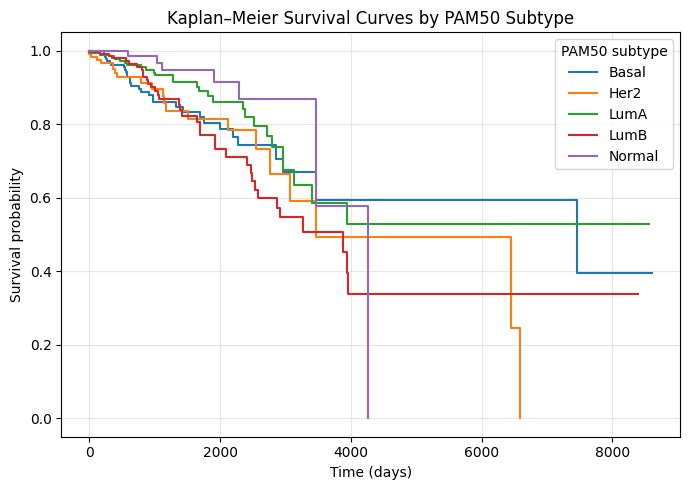

In [88]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

plt.figure(figsize=(7, 5))

for subtype in sorted(pam50_aligned["PAM50_subtype"].unique()):
    mask = pam50_aligned["PAM50_subtype"] == subtype
    
    kmf.fit(
        durations=survival_pam50.loc[mask, "time"],
        event_observed=survival_pam50.loc[mask, "event"],
        label=subtype
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Survival Curves by PAM50 Subtype")
plt.xlabel("Time (days)")
plt.ylabel("Survival probability")
plt.legend(title="PAM50 subtype")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [89]:
from lifelines.statistics import multivariate_logrank_test

lr = multivariate_logrank_test(
    event_durations=survival_pam50["time"].values,
    groups=pam50_aligned["PAM50_subtype"].values,
    event_observed=survival_pam50["event"].values
)

print("Multigroup log-rank test (PAM50):")
print(f"  Test statistic = {lr.test_statistic}")
print(f"  p-value        = {lr.p_value}")


Multigroup log-rank test (PAM50):
  Test statistic = 10.450989696868033
  p-value        = 0.033478832165735266


## Additional post-hoc analyses

In [ ]:
# -------------------------------------------------
# Post-hoc 1: Cluster–clinical enrichment
# -------------------------------------------------
import numpy as np
import pandas as pd
from scipy import stats

# 0. Prepare: make sure we have cluster labels aligned to X_surv

print("Cluster labels length:", len(labels_k5_ref))
assert len(labels_k5_ref) == clinical_core_aligned.shape[0]

clinical_clusters = clinical_core_aligned.copy()
clinical_clusters["cluster"] = labels_k5_ref  # 0..4

# Helper to pretty-print p-values
def _fmt_p(p):
    if p < 1e-4:
        return f"{p:.1e}"
    return f"{p:.4f}"

# 1. Stage (numeric): Kruskal–Wallis across clusters
stage_var = "stage_pathologic_overall_num"
stage_df = clinical_clusters.dropna(subset=[stage_var])

groups_stage = [stage_df.loc[stage_df["cluster"] == k, stage_var].values
                for k in sorted(stage_df["cluster"].unique())]

kw_stat_stage, kw_p_stage = stats.kruskal(*groups_stage)
print("Stage (numeric) ~ cluster:")
print(f"  Kruskal–Wallis H = {kw_stat_stage:.3f}, p = {_fmt_p(kw_p_stage)}")
print("  N used =", len(stage_df), "of", clinical_clusters.shape[0], "\n")

# 2. Age: Kruskal–Wallis across clusters
age_var = "age_at_diagnosis"
age_df = clinical_clusters.dropna(subset=[age_var])

groups_age = [age_df.loc[age_df["cluster"] == k, age_var].values
              for k in sorted(age_df["cluster"].unique())]

kw_stat_age, kw_p_age = stats.kruskal(*groups_age)
print("Age at diagnosis ~ cluster:")
print(f"  Kruskal–Wallis H = {kw_stat_age:.3f}, p = {_fmt_p(kw_p_age)}")
print("  N used =", len(age_df), "of", clinical_clusters.shape[0], "\n")

# Helper to do chi-square on a contingency table
def chi2_for_var(df, varname, min_count=5):
    # Optionally collapse rare levels into "Other" to avoid very sparse tables
    counts = df[varname].value_counts()
    rare_levels = counts[counts < min_count].index
    v = df[varname].copy()
    v = v.where(~v.isin(rare_levels), other="Other")
    tab = pd.crosstab(df["cluster"], v)
    chi2, p, dof, expected = stats.chi2_contingency(tab)
    return tab, chi2, p, dof

# 3. T-pathologic (base): chi-square test
for var in ["t_pathologic_base", "n_pathologic_base", "m_pathologic_base"]:
    df_nonmiss = clinical_clusters.dropna(subset=[var])
    tab, chi2, p, dof = chi2_for_var(df_nonmiss, var, min_count=5)
    print(f"{var} ~ cluster (after collapsing rare levels to 'Other'):")
    print(tab)
    print(f"  Chi-square = {chi2:.3f}, dof = {dof}, p = {_fmt_p(p)}")
    print("  N used =", df_nonmiss.shape[0], "of", clinical_clusters.shape[0], "\n")


Cluster labels length: 941
Stage (numeric) ~ cluster:
  Kruskal–Wallis H = 8.228, p = 0.0836
  N used = 849 of 941 

Age at diagnosis ~ cluster:
  Kruskal–Wallis H = 4.531, p = 0.3389
  N used = 941 of 941 

t_pathologic_base ~ cluster (after collapsing rare levels to 'Other'):
t_pathologic_base  Other  T1  T1b  T1c   T2  T3  T4  T4b
cluster                                                 
0                      6  23    6   82  185  36   0    5
1                      1   3    1   22   87  13   3    6
2                      3   5    0   25  100  17   2    3
3                      2   3    3   25   76  11   1    3
4                      3   2    2   22   60  15   0    4
  Chi-square = 37.053, dof = 28, p = 0.1177
  N used = 866 of 941 

n_pathologic_base ~ cluster (after collapsing rare levels to 'Other'):
n_pathologic_base   N0  N1  N1a  N1b  N1mi  N2  N2a  N3  N3a  NX  Other
cluster                                                                
0                  155  41   52    4   

In [91]:
# -------------------------------------------------
# M status: per-cluster proportions (M0 / MX / M1)
# -------------------------------------------------
m_df = clinical_clusters.dropna(subset=["m_pathologic_base"]).copy()

# 1) Per-cluster counts and row-wise percentages
m_counts = pd.crosstab(m_df["cluster"], m_df["m_pathologic_base"])
m_props = m_counts.div(m_counts.sum(axis=1), axis=0)

print("M status counts by cluster:")
print(m_counts, "\n")
print("M status row-wise proportions by cluster:")
print(m_props.round(3), "\n")

# -------------------------------------------------
# 2) Simplified test: M0 vs non-M0
# -------------------------------------------------
m_df["m_simplified"] = np.where(m_df["m_pathologic_base"] == "M0", "M0", "Non-M0")

m_simple_counts = pd.crosstab(m_df["cluster"], m_df["m_simplified"])
chi2_simple, p_simple, dof_simple, expected_simple = stats.chi2_contingency(m_simple_counts)

print("Simplified M status (M0 vs Non-M0) by cluster:")
print(m_simple_counts)
print(f"  Chi-square = {chi2_simple:.3f}, dof = {dof_simple}, p = {_fmt_p(p_simple)}")
print("  N used =", m_df.shape[0], "of", clinical_clusters.shape[0])


M status counts by cluster:
m_pathologic_base   M0  M1  MX
cluster                       
0                  273   7  62
1                  127   6   3
2                  128   3  24
3                  119   2   3
4                   83   0  25 

M status row-wise proportions by cluster:
m_pathologic_base     M0     M1     MX
cluster                               
0                  0.798  0.020  0.181
1                  0.934  0.044  0.022
2                  0.826  0.019  0.155
3                  0.960  0.016  0.024
4                  0.769  0.000  0.231 

Simplified M status (M0 vs Non-M0) by cluster:
m_simplified   M0  Non-M0
cluster                  
0             273      69
1             127       9
2             128      27
3             119       5
4              83      25
  Chi-square = 31.426, dof = 4, p = 2.5e-06
  N used = 865 of 941


In [92]:
# -------------------------------------------------
# Age-based post-hoc: per-cluster summaries + age group χ²
# -------------------------------------------------
import numpy as np
import pandas as pd
from scipy import stats

age_var = "age_at_diagnosis"

# 1) Per-cluster age summaries (mean, median, IQR)
age_desc = (
    clinical_clusters
    .groupby("cluster")[age_var]
    .agg(
        n="count",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
)

print("Per-cluster age at diagnosis (years):")
print(age_desc.round(2), "\n")

# 2) Dichotomized age: <50 vs ≥50, χ² across clusters
age_df = clinical_clusters.dropna(subset=[age_var]).copy()
age_df["age_group_50"] = np.where(age_df[age_var] < 50, "<50", "≥50")

age_counts = pd.crosstab(age_df["cluster"], age_df["age_group_50"])
chi2_age, p_age, dof_age, expected_age = stats.chi2_contingency(age_counts)

print("Age group (<50 vs ≥50) counts by cluster:")
print(age_counts)
print(f"  Chi-square = {chi2_age:.3f}, dof = {dof_age}, p = {_fmt_p(p_age)}")
print("  N used =", age_df.shape[0], "of", clinical_clusters.shape[0])


Per-cluster age at diagnosis (years):
           n   mean  median   q25    q75
cluster                                 
0        375  57.44    58.0  48.0  66.00
1        148  59.76    61.0  50.0  69.00
2        173  57.84    58.0  50.0  66.00
3        132  58.63    58.0  50.0  66.25
4        113  59.54    59.0  48.0  71.00 

Age group (<50 vs ≥50) counts by cluster:
age_group_50  <50  ≥50
cluster               
0             113  262
1              36  112
2              42  131
3              31  101
4              31   82
  Chi-square = 3.899, dof = 4, p = 0.4199
  N used = 941 of 941


In [93]:
# -------------------------------------------------
# Per-dimension clinical association: continuous vars
# -------------------------------------------------
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Zgraph: shape (941, latent_dim)
print("Z_graph shape:", Z_graph.shape)
n_patients, latent_dim = Z_graph.shape

# Align into a single dataframe
latent_df = pd.DataFrame(Z_graph, columns=[f"z{j}" for j in range(latent_dim)])
latent_df["patient_id"] = clinical_core_aligned["patient_id"].values

clin = clinical_core_aligned.copy()

# Helper: Spearman for each latent dimension vs a continuous clinical variable
def spearman_scan(varname):
    df = pd.concat(
        [latent_df.set_index("patient_id"),
         clin.set_index("patient_id")[[varname]]],
        axis=1
    ).dropna(subset=[varname])

    n_used = df.shape[0]
    rhos = []
    ps = []

    for j in range(latent_dim):
        z = df[f"z{j}"].values
        y = df[varname].values
        rho, p = stats.spearmanr(z, y)
        rhos.append(rho)
        ps.append(p)

    rhos = np.array(rhos)
    ps = np.array(ps)

    # FDR correction
    rej, p_fdr, _, _ = multipletests(ps, alpha=0.05, method="fdr_bh")

    res = pd.DataFrame({
        "dim": np.arange(latent_dim),
        "rho": rhos,
        "p_raw": ps,
        "p_fdr": p_fdr,
        "significant": rej,
    }).sort_values("p_fdr")

    return res, n_used

# 1) Age at diagnosis
age_res, n_age = spearman_scan("age_at_diagnosis")
print("Age ~ z_j (Spearman):")
print("  N used:", n_age)
print(age_res.head(10).round(4), "\n")

# 2) Pathologic stage (numeric)
stage_res, n_stage = spearman_scan("stage_pathologic_overall_num")
print("Stage (numeric) ~ z_j (Spearman):")
print("  N used:", n_stage)
print(stage_res.head(10).round(4))


age_res, n_age = spearman_scan("age_at_diagnosis")
stage_res, n_stage = spearman_scan("stage_pathologic_overall_num")

prop_dims_sig_age   = age_res["significant"].mean()    # fraction in [0,1]
prop_dims_sig_stage = stage_res["significant"].mean()
print("prop_dims_sig_age = ", prop_dims_sig_age)
print("\nprop_dims_sig_stage = ", prop_dims_sig_stage)


Z_graph shape: (941, 64)
Age ~ z_j (Spearman):
  N used: 941
    dim     rho   p_raw   p_fdr  significant
45   45 -0.1131  0.0005  0.0220         True
37   37 -0.1105  0.0007  0.0220         True
3     3  0.0936  0.0041  0.0232         True
31   31  0.0977  0.0027  0.0232         True
38   38 -0.0957  0.0033  0.0232         True
39   39  0.0993  0.0023  0.0232         True
26   26  0.1007  0.0020  0.0232         True
17   17  0.0989  0.0024  0.0232         True
48   48 -0.0981  0.0026  0.0232         True
62   62 -0.0939  0.0039  0.0232         True 

Stage (numeric) ~ z_j (Spearman):
  N used: 849
    dim     rho   p_raw   p_fdr  significant
2     2  0.0677  0.0486  0.4239        False
13   13  0.0715  0.0374  0.4239        False
50   50 -0.0688  0.0451  0.4239        False
59   59  0.0857  0.0125  0.4239        False
43   43 -0.0665  0.0529  0.4239        False
44   44  0.0763  0.0263  0.4239        False
47   47 -0.0690  0.0445  0.4239        False
34   34  0.0664  0.0530  0.4239   

In [94]:
# -------------------------------------------------
# Robust KW scan for categorical T/N/M
# -------------------------------------------------
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

latent_df = pd.DataFrame(Z_graph, columns=[f"z{j}" for j in range(Z_graph.shape[1])])
latent_df["patient_id"] = clinical_core_aligned["patient_id"].values

clin = clinical_core_aligned.copy().set_index("patient_id")
latent_df = latent_df.set_index("patient_id")

def kw_scan(varname, min_count=10):
    df = pd.concat([latent_df, clin[[varname]]], axis=1).dropna(subset=[varname])

    # If fewer than 2 categories, KW is not defined
    if df[varname].nunique() < 2:
        print(f"{varname}: <2 categories after dropna; skipping.")
        return None

    counts_raw = df[varname].value_counts()

    # Collapse very rare levels to "Other"
    rare = counts_raw[counts_raw < min_count].index
    df[varname] = df[varname].where(~df[varname].isin(rare), other="Other")

    levels = sorted(df[varname].unique())
    if len(levels) < 2:
        print(f"{varname}: <2 categories after collapsing rare levels; skipping.")
        return None

    n_used = df.shape[0]
    Hs = []
    ps = []

    for j in range(Z_graph.shape[1]):
        groups = [df.loc[df[varname] == lvl, f"z{j}"].values for lvl in levels]
        # Defensive: if any group becomes empty, skip this dimension
        if any(len(g) == 0 for g in groups):
            Hs.append(np.nan)
            ps.append(1.0)
            continue
        H, p = stats.kruskal(*groups)
        Hs.append(H)
        ps.append(p)

    Hs = np.array(Hs)
    ps = np.array(ps)

    # FDR only on finite p-values
    finite_mask = np.isfinite(ps)
    rej = np.zeros_like(ps, dtype=bool)
    p_fdr = np.full_like(ps, np.nan, dtype=float)

    if finite_mask.sum() > 0:
        rej_f, p_fdr_f, _, _ = multipletests(ps[finite_mask], alpha=0.05, method="fdr_bh")
        rej[finite_mask] = rej_f
        p_fdr[finite_mask] = p_fdr_f

    res = pd.DataFrame({
        "dim": np.arange(Z_graph.shape[1]),
        "H": Hs,
        "p_raw": ps,
        "p_fdr": p_fdr,
        "significant": rej,
    }).sort_values("p_fdr")

    return res, n_used, levels, counts_raw

for var in ["t_pathologic_base", "n_pathologic_base", "m_pathologic_base"]:
    out = kw_scan(var, min_count=10)
    if out is None:
        continue
    res, n_used, levels, counts = out
    print(f"\n{var} ~ z_j (Kruskal–Wallis across {len(levels)} levels):")
    print("  Levels used:", levels)
    print("  Raw counts:\n", counts, "\n")
    print("  N used:", n_used)
    print(res.head(10).round(4))

    frac_sig = res["significant"].mean()

    if var == "t_pathologic_base":
        prop_dims_sig_T = frac_sig
        print('prop_dims_sig_T = ', prop_dims_sig_T)
    elif var == "n_pathologic_base":
        prop_dims_sig_N = frac_sig
        print('\nprop_dims_sig_N = ', prop_dims_sig_N)
    elif var == "m_pathologic_base":
        prop_dims_sig_M = frac_sig  
        print('\nprop_dims_sig_M = ', prop_dims_sig_M)





t_pathologic_base ~ z_j (Kruskal–Wallis across 7 levels):
  Levels used: ['Other', 'T1', 'T1b', 'T1c', 'T2', 'T3', 'T4b']
  Raw counts:
 t_pathologic_base
T2     508
T1c    176
T3      92
T1      36
T4b     21
T1b     12
T4       6
T1a      4
Tis      4
T4d      3
TX       2
T2b      1
T2a      1
Name: count, dtype: int64 

  N used: 866
    dim        H   p_raw   p_fdr  significant
17   17  19.5363  0.0033  0.0306         True
18   18  21.3451  0.0016  0.0306         True
16   16  21.5591  0.0015  0.0306         True
39   39  19.6718  0.0032  0.0306         True
57   57  20.1049  0.0027  0.0306         True
45   45  19.5428  0.0033  0.0306         True
37   37  19.9587  0.0028  0.0306         True
3     3  18.8722  0.0044  0.0347         True
48   48  18.6091  0.0049  0.0347         True
53   53  18.2209  0.0057  0.0365         True
prop_dims_sig_T =  0.265625

n_pathologic_base ~ z_j (Kruskal–Wallis across 11 levels):
  Levels used: ['N0', 'N1', 'N1a', 'N1b', 'N1mi', 'N2', 'N2a', 'N

In [95]:
# -------------------------------------------------
# Survival data with cluster labels (graph-DAE)
# -------------------------------------------------
import numpy as np
import pandas as pd

# Use the aligned survival table
surv = surv_aligned.copy()
surv["patient_id"] = clinical_core_aligned["patient_id"].values

# Add cluster labels (ensure same order)
cluster_labels = np.asarray(labels_k5_ref)
surv["cluster"] = cluster_labels  # 0..4

# Add age (from clinical_core_aligned, already aligned)
surv["age_at_diagnosis"] = clinical_core_aligned["age_at_diagnosis"].values

print(surv.head())
print("Shape:", surv.shape)


     patient_id    time  event  age_at_diagnosis  cluster
0  TCGA-3C-AAAU  4047.0      0                55        0
1  TCGA-3C-AALI  4005.0      0                50        2
2  TCGA-3C-AALJ  1474.0      0                62        4
3  TCGA-3C-AALK  1448.0      0                52        0
4  TCGA-4H-AAAK   348.0      0                50        4
Shape: (941, 5)


In [96]:
# -------------------------------------------------
# Log-rank test: clusters vs survival
# -------------------------------------------------
from lifelines.statistics import logrank_test, multivariate_logrank_test

# Multigroup log-rank across all 5 clusters
results_lr = multivariate_logrank_test(
    surv["time"], surv["cluster"], surv["event"]
)

print("Log-rank test: cluster (K=5) vs survival")
print(f"  chi-square = {results_lr.test_statistic:.3f}, p = {results_lr.p_value:.4f}")


Log-rank test: cluster (K=5) vs survival
  chi-square = 3.299, p = 0.5091


In [97]:
# -------------------------------------------------
# Cox models: cluster only, and cluster + age
# -------------------------------------------------
from lifelines import CoxPHFitter

# Prepare dataframe for lifelines (one-hot encode clusters)
df_cox = surv[["time", "event", "cluster", "age_at_diagnosis"]].copy()

# Make cluster a categorical with a reference (cluster 0)
df_cox["cluster"] = df_cox["cluster"].astype("category")

# 3a) Cox: cluster only
df_cluster = df_cox[["time", "event", "cluster"]].copy()
df_cluster = pd.get_dummies(df_cluster, columns=["cluster"], drop_first=True)

cph_cluster = CoxPHFitter()
cph_cluster.fit(df_cluster, duration_col="time", event_col="event")

print("\nCox model: cluster only")
cph_cluster.print_summary(columns=["coef", "exp(coef)", "p"])

# 3b) Cox: cluster + age
df_cluster_age = df_cox.copy()
df_cluster_age = pd.get_dummies(df_cluster_age, columns=["cluster"], drop_first=True)

cph_cluster_age = CoxPHFitter()
cph_cluster_age.fit(df_cluster_age, duration_col="time", event_col="event")

print("\nCox model: cluster + age")
cph_cluster_age.print_summary(columns=["coef", "exp(coef)", "p"])



Cox model: cluster only


<lifelines.CoxPHFitter: fitted with 941 total observations, 817 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 941
number of events observed = 124
   partial log-likelihood = -687.98
         time fit was run = 2026-09-11 03:54:26 UTC

---
           coef exp(coef)    p
covariate                     
cluster_1  0.42      1.52 0.11
cluster_2  0.23      1.25 0.36
cluster_3  0.01      1.01 0.97
cluster_4  0.02      1.02 0.96
---
Concordance = 0.53
Partial AIC = 1383.96
log-likelihood ratio test = 3.13 on 4 df
-log2(p) of ll-ratio test = 0.90


Cox model: cluster + age


<lifelines.CoxPHFitter: fitted with 941 total observations, 817 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 941
number of events observed = 124
   partial log-likelihood = -674.94
         time fit was run = 2026-09-11 03:54:26 UTC

---
                  coef exp(coef)      p
covariate                              
age_at_diagnosis  0.04      1.04 <0.005
cluster_1         0.35      1.42   0.18
cluster_2         0.14      1.15   0.57
cluster_3        -0.03      0.97   0.91
cluster_4        -0.04      0.96   0.91
---
Concordance = 0.67
Partial AIC = 1359.88
log-likelihood ratio test = 29.21 on 5 df
-log2(p) of ll-ratio test = 15.53

In [98]:
# -------------------------------------------------
# Does cluster add beyond age?
# Compare: age-only vs age + clusters
# -------------------------------------------------
# Age-only Cox
df_age = surv[["time", "event", "age_at_diagnosis"]].copy()

cph_age = CoxPHFitter()
cph_age.fit(df_age, duration_col="time", event_col="event")

# Compute LR statistic: 2*(LL_full - LL_reduced)
ll_age = cph_age.log_likelihood_
ll_cluster_age = cph_cluster_age.log_likelihood_
lr_stat = 2 * (ll_cluster_age - ll_age)
df_diff = df_cluster_age.shape[1] - df_age.shape[1]  # extra parameters (cluster dummies)
from scipy.stats import chi2
p_lr = chi2.sf(lr_stat, df_diff)

print("\nLikelihood ratio test: age vs age + cluster")
print(f"  LR stat = {lr_stat:.3f}, df = {df_diff}, p = {p_lr:.4f}")
print(f"  C-index age-only       = {cph_age.concordance_index_:.3f}")
print(f"  C-index age+cluster    = {cph_cluster_age.concordance_index_:.3f}")



Likelihood ratio test: age vs age + cluster
  LR stat = 2.277, df = 4, p = 0.6850
  C-index age-only       = 0.661
  C-index age+cluster    = 0.667


In [99]:
# -------------------------------------------------
# PAM50 Chi-square: 
# Is the PAM50 distribution the same in all clusters?
# -------------------------------------------------

import pandas as pd
from scipy.stats import chi2_contingency

df = pd.DataFrame({
    "cluster": cluster_labels,          # length n
    "pam50": pam50_labels,      # same patients
}).dropna()

ct = pd.crosstab(df["cluster"], df["pam50"])
chi2, p, dof, expected = chi2_contingency(ct)

pam50_chi2 = chi2
pam50_chi2_p = p

print(f"  Chi-square = {chi2:.3f}, dof = {dof}, p = {_fmt_p(p)}")


  Chi-square = 111.983, dof = 16, p = 1.9e-16


Explained variance PC1, PC2: [0.52482057 0.2792252 ]


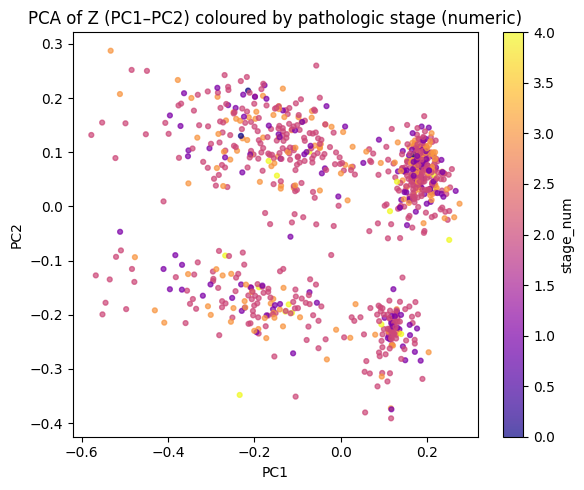

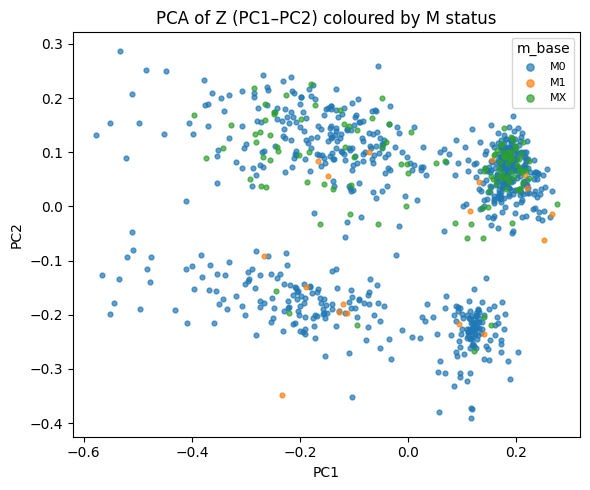

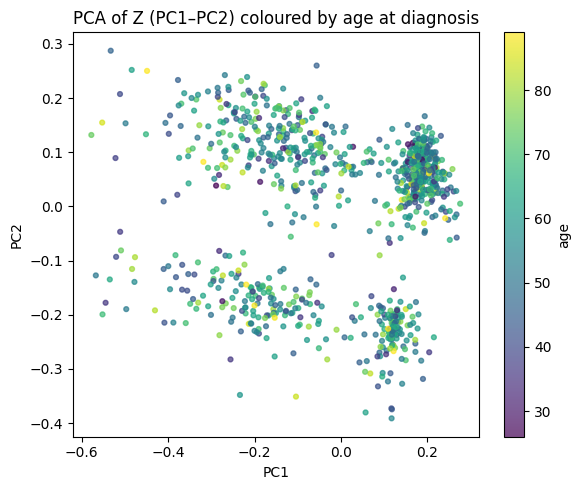

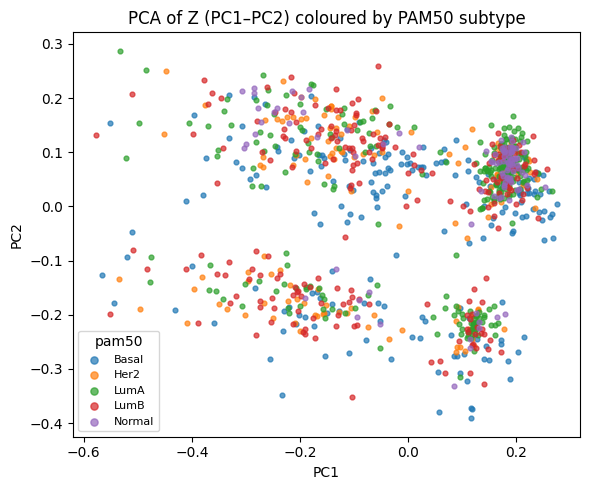

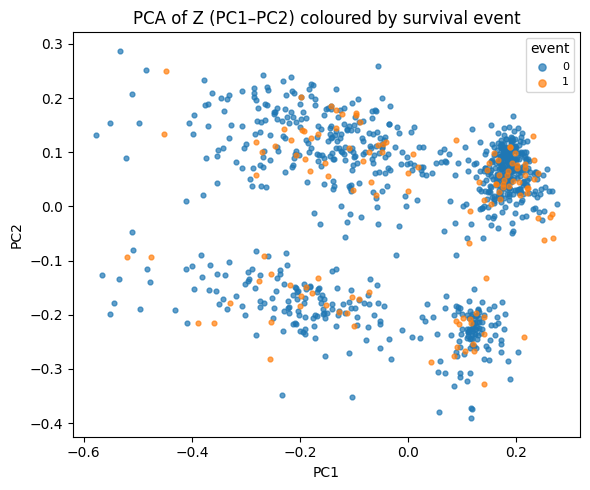

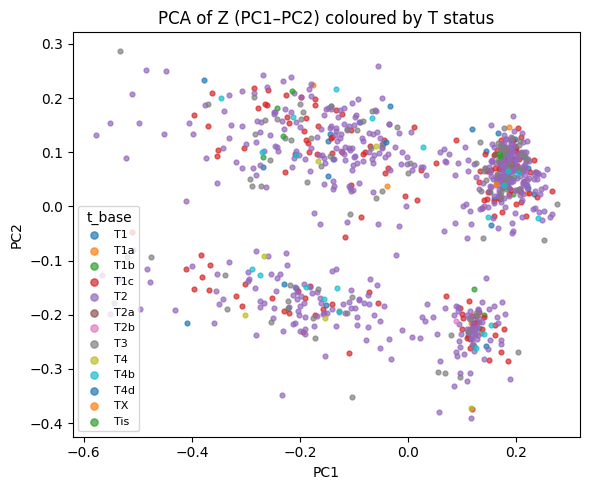

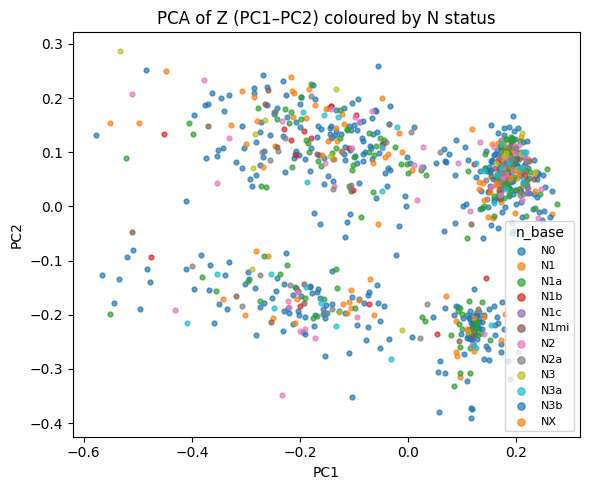

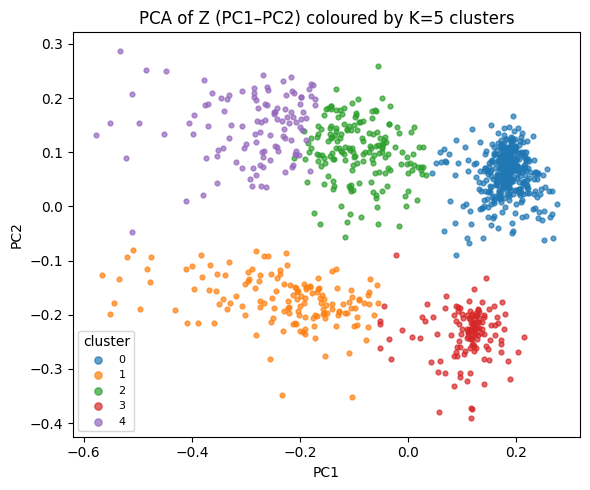

In [ ]:
# -------------------------------------------------
# PCA visualisation of Z with extended clinical overlays
# -------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

Z = Z_graph  # (941, 64)
clin = clinical_core_aligned.copy()

# 1) Fit PCA on Z
pca = PCA(n_components=2, random_state=0)
Z_pc = pca.fit_transform(Z)

pc_df = pd.DataFrame(Z_pc, columns=["PC1", "PC2"])

# Existing variables
pc_df["stage_num"] = clin["stage_pathologic_overall_num"].values
pc_df["m_base"] = clin["m_pathologic_base"].values
pc_df["age"] = clin["age_at_diagnosis"].values

# Adjust survival info
# Make survival a proper index by patient_id
surv = surv_df_final.set_index("patient_id")
# Reindex to the clinical/Z order
events_aligned = surv.reindex(clin["patient_id"])["event"]  # length 941 with NaNs



pc_df["pam50"] = pam50_labels                            # e.g. LumA, LumB, ...
pc_df["event"] = pc_df["event"] = events_aligned.values  # 0/1 survival event
pc_df["t_base"] = clin["t_pathologic_base"].values       # T categories
pc_df["n_base"] = clin["n_pathologic_base"].values       # N categories
# Optionally cluster labels
pc_df["cluster"] = cluster_labels                       # from KMeans on Z

print("Explained variance PC1, PC2:", pca.explained_variance_ratio_[:2])

def plot_scatter(df, color_col, title, cmap="viridis", is_categorical=False):
    plt.figure(figsize=(6, 5))
    if is_categorical:
        categories = df[color_col].astype(str).fillna("NA")
        uniq = sorted(categories.unique())
        for c in uniq:
            mask = categories == c
            plt.scatter(df.loc[mask, "PC1"],
                        df.loc[mask, "PC2"],
                        s=12,
                        alpha=0.7,
                        label=c)
        plt.legend(title=color_col, fontsize=8, markerscale=1.5)
    else:
        sc = plt.scatter(df["PC1"], df["PC2"],
                         c=df[color_col],
                         s=12,
                         cmap=cmap,
                         alpha=0.7)
        cbar = plt.colorbar(sc)
        cbar.set_label(color_col)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Existing overlays
plot_scatter(
    pc_df.dropna(subset=["stage_num"]),
    "stage_num",
    "PCA of Z (PC1–PC2) coloured by pathologic stage (numeric)",
    cmap="plasma",
    is_categorical=False,
)

plot_scatter(
    pc_df.dropna(subset=["m_base"]),
    "m_base",
    "PCA of Z (PC1–PC2) coloured by M status",
    is_categorical=True,
)

plot_scatter(
    pc_df.dropna(subset=["age"]),
    "age",
    "PCA of Z (PC1–PC2) coloured by age at diagnosis",
    cmap="viridis",
    is_categorical=False,
)

# New overlays

# PAM50
plot_scatter(
    pc_df.dropna(subset=["pam50"]),
    "pam50",
    "PCA of Z (PC1–PC2) coloured by PAM50 subtype",
    is_categorical=True,
)

# Survival event (0/1, but treat as categorical for clearer legend)
# (only patients with survival data are kept)
plot_scatter(
    pc_df.dropna(subset=["event"]),
    "event",
    "PCA of Z (PC1–PC2) coloured by survival event",
    is_categorical=True,
)

# T and N status
plot_scatter(
    pc_df.dropna(subset=["t_base"]),
    "t_base",
    "PCA of Z (PC1–PC2) coloured by T status",
    is_categorical=True,
)

plot_scatter(
    pc_df.dropna(subset=["n_base"]),
    "n_base",
    "PCA of Z (PC1–PC2) coloured by N status",
    is_categorical=True,
)

# Optional: cluster overlay for completeness
plot_scatter(
    pc_df.dropna(subset=["cluster"]),
    "cluster",
    "PCA of Z (PC1–PC2) coloured by K=5 clusters",
    is_categorical=True,
)


### Save all outputs

In [101]:
# ============================================================
# Zip all files in /kaggle/working for download
# ============================================================

import os
import zipfile

WORK_DIR = "/kaggle/working/"
ZIP_PATH = "/kaggle/working/GraphDAE-best.zip"

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for foldername, subfolders, filenames in os.walk(WORK_DIR):
        for filename in filenames:
            file_path = os.path.join(foldername, filename)

            # Avoid zipping the zip itself
            if file_path == ZIP_PATH:
                continue

            arcname = os.path.relpath(file_path, WORK_DIR)
            zipf.write(file_path, arcname)

print("Zipped all outputs to:")
print(ZIP_PATH)

Zipped all outputs to:
/kaggle/working/GraphDAE-best.zip
